# Red3-FDC-2026: An Offset-Preserving, Deduplicated Dataset of FD&C Red No. 3 Declarations in U.S. Branded Foods, with Human-Adjudicated Validation Labels

**Savyata Regmi** · ORCID: [0009-0006-7736-9967](https://orcid.org/0009-0006-7736-9967)

Version 1.0.0 · November 2026 · DOI: [10.5281/zenodo.24488536](https://doi.org/10.5281/zenodo.24488536)

Code: MIT · Tables and labels: CC BY 4.0 · Source data: USDA FoodData Central (CC0 1.0)

**Artifact Overview.** This self-contained pipeline downloads the USDA FoodData Central (FDC) Branded Foods archive, verifies archive integrity via SHA-256 and CRC checks, classifies ingredient statements using deterministic offset-preserving rules, deduplicates product identities and formulations, and constructs a design-weighted, human-adjudicated validation sample.

**Scope & Epistemic Boundaries.** This pipeline measures whether a database ingredient statement *declares* FD&C Red No. 3. A declaration is a property of a database record; it does not establish chemical presence, retail shelf availability, physical reformulation, or regulatory non-compliance.

| Analysis Unit | Definition | Primary Analytical Use |
| :--- | :--- | :--- |
| **Source Record** | One submitted FDC database entry (`fdc_id`) | Provenance, rule ablation, mention-level offsets |
| **Latest Barcode** | Most recent record for one US-market valid GTIN | Primary product-level prevalence estimates |
| **Declared Formulation** | Records sharing normalized identity **and** full ingredient hash | Manufacturer breadth and SKU proliferation analysis |

**Declaration Taxonomy.**
- `detected`: Unnegated match to a permitted FDA declaration form (`FD&C Red No. 3`, `Red 3`, `Erythrosine`, etc.).
- `review`: Non-FDA synonym (`E127`, `INS 127`, `CI 45430`), possible negation near a match, or a conditional clause (`may contain`, `if decorated`). At the latest-barcode level only: unresolved or conflicting GTIN chronology.
- `not_detected`: Interpretable ingredient statement with no candidate match (*not* proof of chemical absence).
- `unknown`: Missing ingredient text or recognized placeholder (`N/A`, `none`, `not available`).

**Deliberately Excluded.** Shelf-decay projection, OCR/image verification, and compliance-velocity inference from `modified_date` (see Section 28 for formal limitations).

## 1. Configuration

**Objective:** Define pinned dataset identifiers, fixed reference timestamps, directory paths, and deterministic random seeds. 

**Inputs:** User parameters (`RELEASE_DATE`, `ANALYSIS_DATE`, `RANDOM_SEED`) | **Outputs:** Run directory tree (`data/`, `outputs/consolidated_runs/<RUN_ID>/`)

**Methodological Note:** `ANALYSIS_DATE` (`2026-11-21`) is pinned rather than dynamically computed from wall-clock time so cumulative freshness bands remain invariant across reruns of the same snapshot.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, html, json, os, re, shutil, sys, unicodedata, urllib.request, uuid, zipfile

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline

PROJECT_FOLDER = Path.cwd().resolve()
SHOW_ABSOLUTE_PATHS = False  

def shown(path) -> str:
    """A path for printing: relative to the project folder unless SHOW_ABSOLUTE_PATHS."""
    path = Path(path)
    if SHOW_ABSOLUTE_PATHS:
        return str(path)
    try:
        return path.resolve().relative_to(PROJECT_FOLDER).as_posix()
    except ValueError:
        return path.name


RELEASE_DATE   = "2026-10-29"   
ANALYSIS_DATE  = "2026-11-21"   
CHECK_FOR_NEWER_RELEASE = True 

RELEASE_INDEX_URL = "https://fdc.nal.usda.gov/download-datasets.html"
DATASET_BASE_URL  = "https://fdc.nal.usda.gov/fdc-datasets/"
ARCHIVE_NAME      = f"FoodData_Central_branded_food_csv_{RELEASE_DATE}.zip"
ARCHIVE_URL       = DATASET_BASE_URL + ARCHIVE_NAME
REQUIRED_TABLES   = ("food.csv", "branded_food.csv")


EXPECTED_TABLE_SHA256 = {
    "2026-10-29": {
        "food.csv":         "505288ee4ae062805181bd8b5c034efa9c682ceb58a590ef2476fa46cc9622d3",
        "branded_food.csv": "a68b6ed1ce76182fa4eb7d1730a4fb2b49d2c683ca9d1dfcfc51c1a03c3b7013",
    },
}
KNOWN_ARCHIVE_SHA256 = {   
    "2026-10-29": (
        "17f1e52ea91854d8c6c266487597bf1dd6ce63441bfe27c9e61f64e2768440c7",
        "8083c1ee3d64d34b2ce5339bfca691b5c46cc675e51a938a64cb7c7eb9eab5e5",
    ),
}


RAW_DIR       = PROJECT_FOLDER / "data" / "raw"
EXTRACT_DIR   = PROJECT_FOLDER / "data" / "extracted" / RELEASE_DATE
PROCESSED_DIR = PROJECT_FOLDER / "data" / "processed"
ANNOTATION_DIR= PROJECT_FOLDER / "data" / "annotations" / "red3_consolidated"
for folder in (RAW_DIR, EXTRACT_DIR, PROCESSED_DIR):
    folder.mkdir(parents=True, exist_ok=True)

ARCHIVE_PATH  = RAW_DIR / ARCHIVE_NAME
MANIFEST_PATH = RAW_DIR / "download_manifest.json"
AUDIT_PARQUET = PROCESSED_DIR / f"products_audit_{RELEASE_DATE}.parquet"
REBUILD_AUDIT = False   

ENABLE_CANONICAL_GROUPING = False
RUN_LLM = False
SAVE_ALIAS_TABLE = False


INGEST_CHUNK = 100_000
BATCH_SIZE = 100_000
CONTEXT_WINDOW = 100
NEGATIVE_SAMPLE_SIZE = 300
FORMULATION_QUEUE_CAP = 500
RANDOM_SEED = 42
FRESHNESS_WINDOWS_MONTHS = (12, 24, 48)


RUN_ID = datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%S_%fZ_") + uuid.uuid4().hex[:8]
RUN_DIR = PROJECT_FOLDER / "outputs" / "consolidated_runs" / RUN_ID
TABLES_DIR, RESULT_DIR, FIGURES_DIR = RUN_DIR / "tables", RUN_DIR / "processed", RUN_DIR / "figures"
for folder in (TABLES_DIR, RESULT_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(RANDOM_SEED)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

display(pd.DataFrame({
    "setting": ["project folder", "release analysed", "analysis date", "archive",
                "extracted tables", "classified table", "run directory", "annotations"],
    "value": [shown(PROJECT_FOLDER), RELEASE_DATE, ANALYSIS_DATE, shown(ARCHIVE_PATH),
              shown(EXTRACT_DIR), shown(AUDIT_PARQUET), shown(RUN_DIR), shown(ANNOTATION_DIR)],
}))

,setting,value
0,project folder,.
1,release analysed,2026-10-29
2,analysis date,2026-11-21
3,archive,data/raw/FoodData_Central_branded_food_csv_2026-10-29.zip
4,extracted tables,data/extracted/2026-10-29
5,classified table,data/processed/products_audit_2026-10-29.parquet
6,run directory,outputs/consolidated_runs/run_20261124T044933_996155Z_db1a115f
7,annotations,data/annotations/red3_consolidated


## 2. Dependencies

Four packages beyond the standard library. The cell reports what is installed and
installs anything missing into the running kernel.

The exact versions are recorded in the QC file at the end and written to
`requirements-installed.txt`, because groupby ordering, null handling in sorts, and
string-dtype behaviour all affect these results. For a reproducible rerun, install from
that file.

In [2]:
import importlib, subprocess
REQUIRED_PACKAGES = {"pandas": "pandas", "numpy": "numpy",
                     "pyarrow": "pyarrow", "matplotlib": "matplotlib"}
missing = []
for module_name, package_name in REQUIRED_PACKAGES.items():
    try:
        importlib.import_module(module_name)
    except ImportError:
        missing.append(package_name)
if missing:
    print("Installing:", ", ".join(missing), flush=True)
    subprocess.run([sys.executable, "-m", "pip", "install", *missing], check=True)
    print("Restart the kernel and run all cells again.")

import importlib.metadata as metadata
installed = {name: metadata.version(name) for name in REQUIRED_PACKAGES.values()}
display(pd.DataFrame.from_dict(installed, orient="index", columns=["installed_version"]))
print("Python:", sys.version.split()[0], f"({shown(sys.executable)})")

freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"],
                        capture_output=True, text=True, check=True)
(PROJECT_FOLDER / "requirements-installed.txt").write_text(freeze.stdout, encoding="utf-8")
print("Environment snapshot written to requirements-installed.txt")
if "file://" in freeze.stdout:
    print("NOTE: requirements-installed.txt contains local file paths (lines with 'file://'). "
          "Replace those lines before publishing the file.")

,installed_version
pandas,3.0.5
numpy,2.5.2
pyarrow,25.0.1
matplotlib,3.11.2


Python: 3.14.7 (python.exe)
Environment snapshot written to requirements-installed.txt


## 3. Download the Official Archive and Record Provenance

**Objective:** Stream the pinned USDA Branded Foods ZIP archive to disk while computing its SHA-256 digest and verifying completeness against `Content-Length`.

**Inputs:** `ARCHIVE_URL`, `RELEASE_INDEX_URL` | **Outputs:** `data/raw/FoodData_Central_branded_food_csv_2026-10-29.zip`, `data/raw/download_manifest.json` 


**Methodological Note:** Incomplete downloads are discarded atomically via `.part` staging. Newer releases on the USDA index are reported for awareness but never adopted automatically.


In [3]:
USER_AGENT = "red3-audit/1.0 (academic data descriptor; stdlib urllib)"
CHUNK = 1 << 20

def _request(url, method="GET"):
    return urllib.request.Request(url, method=method, headers={"User-Agent": USER_AGENT})

def sha256_file(path: Path):
    digest, size = hashlib.sha256(), 0
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(CHUNK), b""):
            digest.update(block); size += len(block)
    return digest.hexdigest(), size

if CHECK_FOR_NEWER_RELEASE:
    try:
        with urllib.request.urlopen(_request(RELEASE_INDEX_URL), timeout=60) as response:
            index_html = response.read().decode("utf-8", errors="replace")
        found = sorted({m.group(1) for m in re.finditer(
            r"FoodData_Central_branded_food_csv_(\d{4}-\d{2}-\d{2})\.zip", index_html)})
        print(f"Official Branded Foods releases listed: {len(found)}"
              f" ({found[0]} .. {found[-1]})" if found else "Release index unreadable.")
        if found and max(found) > RELEASE_DATE:
            print(f"\n*** A NEWER RELEASE EXISTS: {max(found)} (this run uses {RELEASE_DATE}). ***")
            print("Adopting it changes every count. Set RELEASE_DATE deliberately, "
                  "move ANALYSIS_DATE with it, and rerun from Section 1.")
        elif found:
            print(f"{RELEASE_DATE} is the newest release. Up to date.")
    except Exception as error:
        print(f"Release check skipped ({type(error).__name__}: {error}). "
              "This does not affect the analysis.")

if ARCHIVE_PATH.is_file():
    print(f"\nArchive already present; re-hashing {ARCHIVE_PATH.name} ...", flush=True)
    archive_sha256, archive_bytes = sha256_file(ARCHIVE_PATH)
    completed_utc = datetime.fromtimestamp(
        ARCHIVE_PATH.stat().st_mtime, timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
    download_note = "existing local file (not re-downloaded)"
else:
    print(f"\nDownloading {ARCHIVE_URL}", flush=True)
    print("Roughly 450 MB; this is the slow step.", flush=True)
    partial = ARCHIVE_PATH.with_suffix(".zip.part")
    digest, written, milestone = hashlib.sha256(), 0, 0
    try:
        with urllib.request.urlopen(_request(ARCHIVE_URL), timeout=120) as response:
            declared = response.headers.get("Content-Length")
            declared_bytes = int(declared) if declared and declared.isdigit() else None
            with partial.open("wb") as handle:
                for block in iter(lambda: response.read(CHUNK), b""):
                    handle.write(block); digest.update(block); written += len(block)
                    if written - milestone >= 50 * CHUNK:
                        milestone = written
                        print(f"  {written / 1e6:,.0f} MB", flush=True)
        if declared_bytes is not None and written != declared_bytes:
            raise RuntimeError(f"Incomplete download: {written:,} of {declared_bytes:,} bytes. "
                               "Nothing was committed; rerun this cell.")
        partial.replace(ARCHIVE_PATH)
    except BaseException:
        partial.unlink(missing_ok=True)
        raise
    archive_sha256, archive_bytes = digest.hexdigest(), written
    completed_utc = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
    download_note = "downloaded by this notebook"
    print(f"  complete: {written:,} bytes", flush=True)

SNAPSHOT = {
    "url": ARCHIVE_URL, "bytes": archive_bytes, "sha256": archive_sha256,
    "download_completed_utc": completed_utc, "dataset": "branded_food_csv",
    "release_date": RELEASE_DATE, "filename": ARCHIVE_NAME,
    "source_index_url": RELEASE_INDEX_URL, "note": download_note,
   
    "sha256_is_known_packaging": ((archive_sha256 in KNOWN_ARCHIVE_SHA256[RELEASE_DATE])
                                  if RELEASE_DATE in KNOWN_ARCHIVE_SHA256 else None),
}
existing_manifest = (json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
                     if MANIFEST_PATH.is_file() else {})
other_entries = [e for e in existing_manifest.get("datasets", [])
                 if e.get("release_date") != RELEASE_DATE]
MANIFEST_PATH.write_text(json.dumps({
    **{k: v for k, v in existing_manifest.items() if k != "datasets"},
    "manifest_schema": "red3-download-manifest/3",
    "generated_by": "Red3_Complete_Pipeline.ipynb",
    "manifest_updated_utc": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "datasets": other_entries + [SNAPSHOT],
}, indent=2), encoding="utf-8")

print("\nFor the data-availability statement:")
for key in ("url", "bytes", "sha256", "download_completed_utc"):
    value = SNAPSHOT[key]
    print(f"  {key:24s} {value:,}" if isinstance(value, int) else f"  {key:24s} {value}")
if SNAPSHOT["sha256_is_known_packaging"] is False:
    print("  NOTE: this archive hash is not one of the packagings on record for this release. "
          "That alone is not an error; Section 4 checks the table contents.")
elif SNAPSHOT["sha256_is_known_packaging"]:
    print("  The archive hash is one of the known packagings of this release. Cite the table "
          "hashes from Section 4 as the stable identifier.")
print(f"\nManifest: {shown(MANIFEST_PATH)}")

Official Branded Foods releases listed: 15 (2019-12-17 .. 2026-10-29)
2026-10-29 is the newest release. Up to date.

Archive already present; re-hashing FoodData_Central_branded_food_csv_2026-10-29.zip ...

For the data-availability statement:
  url                      https://fdc.nal.usda.gov/fdc-datasets/FoodData_Central_branded_food_csv_2026-10-29.zip
  bytes                    451,954,262
  sha256                   17f1e52ea91854d8c6c266487597bf1dd6ce63441bfe27c9e61f64e2768440c7
  download_completed_utc   2026-11-23T00:27:12Z
  The archive hash is one of the known packagings of this release. Cite the table hashes from Section 4 as the stable identifier.

Manifest: data/raw/download_manifest.json


## 4. Extract with CRC Validation

**Objective:** Validate ZIP member checksums and path safety before extracting `food.csv` and `branded_food.csv`.

**Inputs:** `ARCHIVE_PATH` | **Outputs:** `data/extracted/2026-10-29/food.csv`, `data/extracted/2026-10-29/branded_food.csv`

**Methodological Note:** Full archive CRC validation (`testzip()`) and path-traversal checks execute prior to extraction; unused nutrient tables are omitted to minimize disk footprint. The two extracted tables are then hashed (SHA-256) and checked against the content hashes pinned in Section 1. These table hashes, not the archive hash, are the stable identifier of the release: USDA serves it in more than one ZIP packaging whose members are byte-identical but whose archive hashes differ.


In [4]:
def _safe_member(name: str) -> bool:
    if name.endswith("/"):
        return not name.startswith(("/", "\\"))
    pure = Path(name.replace("\\", "/"))
    return not (pure.is_absolute() or ".." in pure.parts or re.match(r"^[A-Za-z]:", name))

already_extracted = all((EXTRACT_DIR / table).is_file() for table in REQUIRED_TABLES)
if already_extracted:
    print("Required tables already extracted; skipping.")
else:
    with zipfile.ZipFile(ARCHIVE_PATH) as bundle:
        print("Validating archive CRCs ...", flush=True)
        corrupt = bundle.testzip()
        if corrupt is not None:
            raise RuntimeError(f"CRC validation failed for archive member: {corrupt}")
        print("  all members passed.")
        wanted = {}
        for info in bundle.infolist():
            if not _safe_member(info.filename):
                raise RuntimeError(f"Unsafe archive member path: {info.filename!r}")
            leaf = Path(info.filename.replace("\\", "/")).name
            if leaf in REQUIRED_TABLES and not info.is_dir():
                wanted.setdefault(leaf, info)
        absent = [t for t in REQUIRED_TABLES if t not in wanted]
        if absent:
            raise RuntimeError("Archive does not contain: " + ", ".join(absent))
        for leaf, info in wanted.items():
            print(f"  extracting {leaf} ({info.file_size / 1e6:,.0f} MB) ...", flush=True)
            with bundle.open(info) as source, (EXTRACT_DIR / leaf).open("wb") as sink:
                shutil.copyfileobj(source, sink, CHUNK)

FOOD_CSV = EXTRACT_DIR / "food.csv"
BRANDED_CSV = EXTRACT_DIR / "branded_food.csv"

print("Hashing the extracted tables ...", flush=True)
expected_tables = EXPECTED_TABLE_SHA256.get(RELEASE_DATE, {})
TABLE_FINGERPRINTS = {}
for table_path in (FOOD_CSV, BRANDED_CSV):
    table_sha256, table_bytes = sha256_file(table_path)
    pinned = expected_tables.get(table_path.name)
    TABLE_FINGERPRINTS[table_path.name] = {
        "bytes": table_bytes, "sha256": table_sha256,
        "matches_pinned": (table_sha256 == pinned) if pinned else None,
    }
mismatched = [name for name, entry in TABLE_FINGERPRINTS.items()
              if entry["matches_pinned"] is False]
if mismatched:
    raise RuntimeError(
        f"Extracted table(s) differ from the content hash pinned for release {RELEASE_DATE}: "
        + ", ".join(mismatched) + f". Delete {shown(EXTRACT_DIR)} and rerun this cell to "
        "re-extract from the archive. If the mismatch persists, the release content has "
        "changed and every count may differ; to analyse it deliberately, remove this release "
        "from EXPECTED_TABLE_SHA256 in Section 1.")

SNAPSHOT["tables"] = TABLE_FINGERPRINTS
manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
for entry in manifest.get("datasets", []):
    if entry.get("release_date") == RELEASE_DATE:
        entry["tables"] = TABLE_FINGERPRINTS
MANIFEST_PATH.write_text(json.dumps(manifest, indent=2), encoding="utf-8")

display(pd.DataFrame({
    "table": [p.name for p in (FOOD_CSV, BRANDED_CSV)],
    "size_mb": [round(p.stat().st_size / 1e6, 1) for p in (FOOD_CSV, BRANDED_CSV)],
    "path": [shown(p) for p in (FOOD_CSV, BRANDED_CSV)],
    "sha256": [TABLE_FINGERPRINTS[p.name]["sha256"] for p in (FOOD_CSV, BRANDED_CSV)],
    "matches_pinned": [TABLE_FINGERPRINTS[p.name]["matches_pinned"] for p in (FOOD_CSV, BRANDED_CSV)],
}))
if expected_tables:
    print(f"Both tables match the content hashes pinned for release {RELEASE_DATE}.")
else:
    print(f"No content hash is pinned for release {RELEASE_DATE}; the hashes above were "
          "recorded in the manifest but not checked.")

Required tables already extracted; skipping.
Hashing the extracted tables ...


,table,size_mb,path,sha256,matches_pinned
0,food.csv,378.0,data/extracted/2026-10-29/food.csv,505288ee4ae062805181bd8b5c034efa9c682ceb58a590ef2476fa46cc9622d3,True
1,branded_food.csv,960.7,data/extracted/2026-10-29/branded_food.csv,a68b6ed1ce76182fa4eb7d1730a4fb2b49d2c683ca9d1dfcfc51c1a03c3b7013,True


Both tables match the content hashes pinned for release 2026-10-29.


## 5. Inspect the Source Tables

**Objective:** Verify required schema columns in `food.csv` and `branded_food.csv` and report any absent optional fields.
  
**Inputs:** `FOOD_CSV`, `BRANDED_CSV` | **Outputs:** `BRANDED_USE`, `BRANDED_ABSENT` schema diagnostics  

**Methodological Note:** Missing required columns halt execution immediately; missing optional columns degrade gracefully and are explicitly logged.


In [5]:
def read_header(path: Path) -> list[str]:
    return list(pd.read_csv(path, nrows=0, encoding="utf-8-sig").columns)

food_header, branded_header = read_header(FOOD_CSV), read_header(BRANDED_CSV)

FOOD_REQUIRED    = ["fdc_id", "data_type", "description", "publication_date"]
BRANDED_REQUIRED = ["fdc_id", "gtin_upc", "ingredients", "market_country"]
BRANDED_OPTIONAL = ["brand_owner", "brand_name", "subbrand_name", "branded_food_category",
                    "modified_date", "available_date", "discontinued_date",
                    "data_source", "package_weight", "short_description"]

for label, header, required in [("food.csv", food_header, FOOD_REQUIRED),
                                ("branded_food.csv", branded_header, BRANDED_REQUIRED)]:
    absent = [c for c in required if c not in header]
    if absent:
        raise KeyError(f"{label} is missing required column(s): {', '.join(absent)}\n"
                       f"Columns present: {', '.join(header)}")

BRANDED_USE = BRANDED_REQUIRED + [c for c in BRANDED_OPTIONAL if c in branded_header]
BRANDED_ABSENT = [c for c in BRANDED_OPTIONAL if c not in branded_header]
print(f"food.csv columns          : {len(food_header)}")
print(f"branded_food.csv columns  : {len(branded_header)}")
print(f"branded columns used      : {len(BRANDED_USE)}")
if BRANDED_ABSENT:
    print("\nOptional columns NOT in this release (analysis degrades, reported later):")
    for column in BRANDED_ABSENT:
        print(f"  - {column}")

preview = pd.read_csv(BRANDED_CSV, nrows=3, encoding="utf-8-sig",
                      dtype=str, keep_default_na=False)
display(preview[[c for c in ["fdc_id", "brand_owner", "gtin_upc", "market_country",
                             "modified_date"] if c in preview.columns]])
print("\nFirst ingredient statement, exactly as supplied:\n")
print(preview["ingredients"].iloc[0][:600])

food.csv columns          : 8
branded_food.csv columns  : 21
branded columns used      : 14


,fdc_id,brand_owner,gtin_upc,market_country,modified_date
0,1105904,Richardson Oilseed Products (US) Limited,00027000612323,United States,2020-10-02
1,1105905,CAMPBELL SOUP COMPANY,00051000198808,United States,2020-09-12
2,1105906,CAMPBELL SOUP COMPANY,00051000213273,United States,2020-09-01



First ingredient statement, exactly as supplied:

Vegetable Oil


## 6. Deterministic Rule Classifier and Offset-Preserving Normalization

**Objective:** Normalize raw ingredient statements while preserving exact character-index mappings, then assign provisional declaration statuses (`detected`, `review`, `not_detected`, `unknown`).  


**Inputs:** Raw `ingredients` strings, deterministic `SELF_TESTS` | **Outputs:** `normalize_with_map()`, `detect_red3()`, `DETECTOR_SHA256` 

**Methodological Note:**  

1. **Offset-Preserving Normalization:** Strings undergo HTML entity unescaping, Unicode NFKD decomposition, combining-diacritic removal, case folding, and whitespace collapse while tracking origin indices back to the raw string.  

2. **Negation & Conditionality Routing:** Prefix, suffix, and list-level negations plus conditional clauses route matches to `review` rather than discarding them.  

3. **Rule Fingerprinting:** Regex patterns and placeholder vocabularies are hashed into `DETECTOR_SHA256` to key downstream Parquet caches.


In [6]:
_ENTITY = re.compile(r"&(?:#\d{1,7}|#[xX][0-9a-fA-F]{1,6}|[A-Za-z][A-Za-z0-9]{1,31});")


def _unescape_with_map(raw: str):
    pieces, index_map, cursor = [], [], 0
    for match in _ENTITY.finditer(raw):
        pieces.append(raw[cursor:match.start()])
        index_map.extend(range(cursor, match.start()))
        replacement = html.unescape(match.group(0))
        pieces.append(replacement)
        index_map.extend([match.start()] * len(replacement))
        cursor = match.end()
    pieces.append(raw[cursor:])
    index_map.extend(range(cursor, len(raw)))
    return "".join(pieces), index_map


def _fold_with_map(text: str, index_map: list):
    pieces, folded_map = [], []
    for character, origin in zip(text, index_map):
        decomposed = unicodedata.normalize("NFKD", character)
        folded = "".join(c for c in decomposed if not unicodedata.combining(c)).casefold()
        if folded:
            pieces.append(folded)
            folded_map.extend([origin] * len(folded))
    return "".join(pieces), folded_map


def _collapse_with_map(text: str, index_map: list):
    pieces, collapsed_map, pending_space = [], [], False
    for character, origin in zip(text, index_map):
        if character.isspace():
            pending_space = bool(pieces)
            continue
        if pending_space:
            pieces.append(" "); collapsed_map.append(origin); pending_space = False
        pieces.append(character); collapsed_map.append(origin)
    return "".join(pieces), collapsed_map


def normalize_with_map(value: object):
    """Normalized text plus, for each of its characters, the index it came from."""
    raw = "" if value is None or (not isinstance(value, str) and pd.isna(value)) else str(value)
    text, index_map = _unescape_with_map(raw)
    text, index_map = _fold_with_map(text, index_map)
    text, index_map = _collapse_with_map(text, index_map)
    return text, index_map


def normalize(value: object) -> str:
    """HTML unescape + NFKD + diacritic removal + casefold + whitespace collapse."""
    return normalize_with_map(value)[0]


def raw_span(index_map: list, start: int, end: int, raw_length: int):
    """Translate a span in normalized space back to a span in the raw text."""
    if not index_map or start >= len(index_map):
        return (0, 0)
    first = index_map[start]
    last = index_map[min(end, len(index_map)) - 1] + 1
    return (first, min(last, raw_length))

FDA_NAMES = re.compile(
    r"\b(?:(?:(?:F\.?\s*)?D\.?\s*&(?:amp;)?\s*C\.?|FOOD)\s*)?"
    r"RED[\s-]*(?:DYE[\s-]*)?(?:(?:NO\.?|NUMBER)\s*|#\s*)?3(?!\w|\.\d)"
    r"|\bERYTHROSINE\b", re.I,
)
REVIEW_ALIASES = re.compile(
    r"\bE[\s-]*127(?!\w|\.\d)"
    r"|\bINS[\s-]*(?:NO\.?\s*)?127(?!\w|\.\d)"
    r"|\b(?:C\.?\s*I\.?[\s:-]*)?(?:FOOD[\s-]+RED[\s-]+(?:NO\.?\s*)?14|ACID[\s-]+RED[\s-]+51)(?!\w|\.\d)"
    r"|\bC\.?\s*I\.?[\s:-]*(?:NO\.?\s*)?45430(?::1)?(?!\w|[.:]\d)"
    r"|\b(?:DISODIUM[\s-]+)?(?:[2457]['’′]?[\s,]*){4}TETRAIODOFLUORESCEIN\b"
    r"|\bERYTHROSIN[A-Z0-9_]*\b"
    r"|\bRED\s+(?:DYE\s+)?(?:NUMBER\s+|NO\.?\s+)?THREE\b", re.I,
)
NEGATIVE_PREFIX = re.compile(
    r"(?:\b(?:no|without)|\bfree\s+(?:of|from)|\bdoes\s+not\s+contain|\bcontains?\s+no)\s*[-:(]?\s*$", re.I,
)
NEGATIVE_SUFFIX = re.compile(
    r"^\s*(?:[-–—]\s*)?(?:free\b|(?:is\s+)?not\s+(?:used|present|included)\b"
    r"|(?:(?:has\s+been|was|is)\s+)?removed\b|does\s+not\s+(?:appear|occur)\b)", re.I,
)
NEGATIVE_LIST_PREFIX = re.compile(
    r"\b(?:no|without)\s+(?:(?:artificial|synthetic)\s+)?(?:colou?rs?|dyes?)\b[^.;:\n]{0,100}$"
    r"|\b(?:no|without)\s+(?:red|yellow|blue|green)\b[^.;:\n]{0,100}$", re.I,
)
UNRESOLVED_CANDIDATE = re.compile(
    r"\b(?:red\s*(?:dye\s*)?(?:no\.?\s*|#\s*)?0+3|tetraiodofluorescein)\b", re.I)
CONDITIONAL_DECLARATION = re.compile(
    r"\b(?:may\s+(?:also\s+)?contain|if\s+decorated|if\s+(?:the\s+)?product\s+contains)\b", re.I)

US_MARKETS = {"united states", "united states of america", "us", "usa"}
STATUS_ORDER = ["detected", "review", "not_detected", "unknown"]
INGREDIENT_PLACEHOLDERS = {"", "na", "n/a", "none", "null", "unknown", "not available",
                           "not provided", "ingredients not available",
                           "no ingredient information"}
CANDIDATE_SUBSTRINGS = ("red", "erythros", "127", "45430", "tetra")


def detect_red3(value: object, *, normalized_pair=None) -> dict:
    """Conservative provisional classifier. Matching happens on normalized text;
    reported spans and matched text are translated back to the raw statement."""
    raw = "" if value is None or (not isinstance(value, str) and pd.isna(value)) else str(value)
    normalized, index_map = normalize_with_map(raw) if normalized_pair is None else normalized_pair
    blank = {"matched_text": "", "match_spans": "[]",
             "normalization_changed_match": False}
    if normalized in INGREDIENT_PLACEHOLDERS:
        return {"declared_status": "unknown", "review_reason": "missing_ingredients", **blank}
    if not any(term in normalized for term in CANDIDATE_SUBSTRINGS):
        return {"declared_status": "not_detected", "review_reason": "", **blank}

    direct = list(FDA_NAMES.finditer(normalized))
    alias = [m for m in REVIEW_ALIASES.finditer(normalized)
             if not any(m.start() >= d.start() and m.end() <= d.end() for d in direct)]
    matches = sorted(direct + alias, key=lambda m: (m.start(), m.end()))

    reasons = []
    if alias:
        reasons.append("alias_or_unfamiliar_spelling")
    if any(NEGATIVE_PREFIX.search(normalized[max(0, m.start() - 60):m.start()])
           or NEGATIVE_LIST_PREFIX.search(normalized[max(0, m.start() - 120):m.start()])
           or NEGATIVE_SUFFIX.search(normalized[m.end():m.end() + 60]) for m in matches):
        reasons.append("possible_negated_declaration")
    if not matches and UNRESOLVED_CANDIDATE.search(normalized):
        reasons.append("unresolved_candidate_text")

    if (matches or reasons) and CONDITIONAL_DECLARATION.search(normalized):
        reasons.append("possible_conditional_declaration")

    spans = [raw_span(index_map, m.start(), m.end(), len(raw)) for m in matches]
   
    changed = bool(matches) and not FDA_NAMES.search(raw) and not REVIEW_ALIASES.search(raw)
    status = "review" if reasons else ("detected" if direct else "not_detected")
    return {"declared_status": status,
            "matched_text": " | ".join(raw[a:b] for a, b in spans),
            "match_spans": json.dumps([[a, b] for a, b in spans]),
            "review_reason": ";".join(reasons),
            "normalization_changed_match": changed}

DETECTOR_SHA256 = hashlib.sha256("||".join([
    FDA_NAMES.pattern, REVIEW_ALIASES.pattern, NEGATIVE_PREFIX.pattern,
    NEGATIVE_SUFFIX.pattern, NEGATIVE_LIST_PREFIX.pattern, UNRESOLVED_CANDIDATE.pattern,
    CONDITIONAL_DECLARATION.pattern, "|".join(sorted(INGREDIENT_PLACEHOLDERS)),
    "|".join(CANDIDATE_SUBSTRINGS)]).encode("utf-8")).hexdigest()

SELF_TESTS = [
    ("SUGAR, CORN SYRUP, RED 3, BLUE 1.", "detected"),
    ("SUGAR, FD&C RED NO. 3, SALT.", "detected"),
    ("SUGAR, FD&C RED 3 LAKE.", "detected"),
    ("SUGAR, RED #3.", "detected"),
    ("SUGAR, RED DYE NO. 3.", "detected"),
    ("SUGAR, ERYTHROSINE.", "detected"),
    ("SUGAR, FD&amp;C RED NO. 3.", "detected"),
    ("SUGAR, E127, CITRIC ACID.", "review"),
    ("SUGAR, C.I. 45430.", "review"),
    ("SUGAR, ACID RED 51.", "review"),
    ("SUGAR, RED NUMBER THREE.", "review"),
    ("SUGAR, SODIUM ERYTHROSIN.", "review"),
    ("SUGAR, NATURAL FLAVOR. CONTAINS NO RED 3.", "review"),
    ("SUGAR. RED 3 FREE.", "review"),
    ("SUGAR, NO ARTIFICIAL COLORS SUCH AS RED 3.", "review"),
    ("SUGAR, RED 3. MAY CONTAIN MILK.", "review"),
    ("SUGAR, RED 40, BLUE 1, YELLOW 5.", "not_detected"),
    ("SUGAR, FD&C RED NO. 40.", "not_detected"),
    ("SHREDDED WHEAT, REDUCED IRON.", "not_detected"),
    ("SUGAR, RED 30.", "not_detected"),
    ("SUGAR, RED 3000.", "not_detected"),
    ("SUGAR, E129.", "not_detected"),
    ("SUGAR, \u00c9rythrosine, WATER.", "detected"),
    ("SUGAR, \u00c9RYTHROSINE.", "detected"),
    ("SUGAR, RED \uff13, SALT.", "detected"),
    ("SUGAR, FD\uff06C RED NO. 3.", "detected"),
    ("SUGAR, FD&#38;C RED NO. 3.", "detected"),
    ("SUGAR, RED\u00a03, SALT.", "detected"),
    ("SUGAR, INS 127, WATER.", "review"),
    ("SUGAR, INS NO. 127.", "review"),
    ("SUGAR, RED 40, INS 129.", "not_detected"),
    ("", "unknown"),
    ("N/A", "unknown"),
    ("Not available", "unknown"),
]
results = [(text, expected, detect_red3(text)["declared_status"]) for text, expected in SELF_TESTS]
failed = [(t, e, a) for t, e, a in results if e != a]
display(pd.DataFrame(results, columns=["ingredient statement", "expected", "actual"]))
if failed:
    raise AssertionError("Detector self-tests failed: "
                         + "; ".join(f"{t!r} expected {e}, got {a}" for t, e, a in failed))
print(f"All {len(SELF_TESTS)} detector self-tests passed.")
print("Detector fingerprint:", DETECTOR_SHA256)

,ingredient statement,expected,actual
0,"SUGAR, CORN SYRUP, RED 3, BLUE 1.",detected,detected
1,"SUGAR, FD&C RED NO. 3, SALT.",detected,detected
2,"SUGAR, FD&C RED 3 LAKE.",detected,detected
3,"SUGAR, RED #3.",detected,detected
4,"SUGAR, RED DYE NO. 3.",detected,detected
5,"SUGAR, ERYTHROSINE.",detected,detected
6,"SUGAR, FD&amp;C RED NO. 3.",detected,detected
7,"SUGAR, E127, CITRIC ACID.",review,review
8,"SUGAR, C.I. 45430.",review,review
9,"SUGAR, ACID RED 51.",review,review


All 34 detector self-tests passed.
Detector fingerprint: 267c2b303d19b3aa348bb4323978fda3895d6dea79de71f43601a972dddc7122


## 7. Classify Every Record

**Objective:** Perform a streaming chunked join of `branded_food.csv` to `food.csv` (`data_type == "branded_food"`), classify every ingredient statement, and write the cached audit Parquet table.  

**Inputs:** `BRANDED_CSV`, `FOOD_CSV` | **Outputs:** `data/processed/products_audit_2026-10-29_<hash>.parquet`  


**Methodological Note:** The join enforces `validate="many_to_one"` to prevent silent row multiplication. GTINs (`gtin_key`) are accepted only as exact 8-, 12-, 13-, or 14-digit ASCII strings without zero-padding guesses. No records are filtered at ingest.


In [7]:
AUDIT_COLUMNS = ["fdc_id", "gtin_key", "gtin_upc", "brand_owner", "brand_name",
                 "subbrand_name", "package_weight", "food_description",
                 "branded_food_category", "food_publication_date", "ingredients",
                 "modified_date", "available_date", "discontinued_date",
                 "market_country", "data_source", "declared_status", "matched_text",
                 "match_spans", "review_reason", "ingredient_digest", "food_record_missing",
                 "normalization_changed_match"]
GTIN_SYNTAX = re.compile(r"\d{8}|\d{12}|\d{13}|\d{14}")


AUDIT_PARQUET = AUDIT_PARQUET.with_name(
    f"products_audit_{RELEASE_DATE}_{DETECTOR_SHA256[:8]}.parquet")
print("Classified table for this detector version:", AUDIT_PARQUET.name)
READ_OPTIONS = dict(dtype=str, keep_default_na=False, encoding="utf-8-sig")

if AUDIT_PARQUET.is_file() and not REBUILD_AUDIT:
    print(f"Classified table already present: {AUDIT_PARQUET.name}")
    print("Set REBUILD_AUDIT = True in Section 1 to reclassify.")
else:
    print("Loading branded-food descriptions from food.csv ...", flush=True)
    description_parts = []
    with pd.read_csv(FOOD_CSV, usecols=FOOD_REQUIRED, chunksize=500_000, **READ_OPTIONS) as reader:
        for chunk in reader:
            selected = chunk.loc[chunk["data_type"].str.strip().eq("branded_food"),
                                 ["fdc_id", "description", "publication_date"]]
            if not selected.empty:
                description_parts.append(selected)
    descriptions = pd.concat(description_parts, ignore_index=True)
    descriptions["fdc_id"] = descriptions["fdc_id"].astype("int64")
    if descriptions["fdc_id"].duplicated().any():
        raise ValueError("Duplicate fdc_id values in food.csv; the join would multiply rows.")
    descriptions = descriptions.rename(columns={"description": "food_description",
                                                "publication_date": "food_publication_date"})
    print(f"  {len(descriptions):,} branded-food descriptions", flush=True)
    del description_parts

    writer, total, status_tally = None, 0, {s: 0 for s in STATUS_ORDER}
    try:
        with pd.read_csv(BRANDED_CSV, usecols=BRANDED_USE,
                         chunksize=INGEST_CHUNK, **READ_OPTIONS) as reader:
            for chunk in reader:
                chunk["fdc_id"] = chunk["fdc_id"].astype("int64")
                merged = chunk.merge(descriptions, on="fdc_id", how="left",
                                     validate="many_to_one", indicator="_join")
                merged["food_record_missing"] = merged["_join"].eq("left_only")
                merged = merged.drop(columns="_join")
                for column in AUDIT_COLUMNS:
                    if column not in merged.columns:
                        merged[column] = ""

                pairs = [normalize_with_map(t) for t in merged["ingredients"]]
                normalized = [p[0] for p in pairs]
                verdicts = [detect_red3(raw, normalized_pair=pair)
                            for raw, pair in zip(merged["ingredients"], pairs)]
                merged["declared_status"] = [v["declared_status"] for v in verdicts]
                merged["matched_text"] = [v["matched_text"] for v in verdicts]
                merged["match_spans"] = [v["match_spans"] for v in verdicts]
                merged["review_reason"] = [v["review_reason"] for v in verdicts]
                merged["normalization_changed_match"] = [
                    v["normalization_changed_match"] for v in verdicts]
                merged["ingredient_digest"] = [
                    hashlib.sha256(n.encode("utf-8")).hexdigest()[:32] for n in normalized]

                upc = merged["gtin_upc"].fillna("").astype(str).str.strip()
                merged["gtin_key"] = upc.where(upc.str.fullmatch(GTIN_SYNTAX).fillna(False), "")

                for status, count in merged["declared_status"].value_counts().items():
                    status_tally[status] = status_tally.get(status, 0) + int(count)
                out = merged[AUDIT_COLUMNS].astype(
                    {"fdc_id": "int64", "food_record_missing": "bool",
                     "normalization_changed_match": "bool"})
                table = pa.Table.from_pandas(out, preserve_index=False)
                if writer is None:
                    writer = pq.ParquetWriter(AUDIT_PARQUET, table.schema, compression="snappy")
                writer.write_table(table)
                total += len(out)
                if total % (INGEST_CHUNK * 5) == 0:
                    print(f"  classified {total:,} records", flush=True)
    finally:
        if writer is not None:
            writer.close()
    print(f"\nClassified {total:,} records -> {AUDIT_PARQUET.name}")
    display(pd.Series(status_tally).rename("records").to_frame())
    del descriptions

Classified table for this detector version: products_audit_2026-10-29_267c2b30.parquet
Classified table already present: products_audit_2026-10-29_267c2b30.parquet
Set REBUILD_AUDIT = True in Section 1 to reclassify.


## 8. Load the Classified Table

**Objective:** Open the cached audit Parquet file and map physical column names to canonical analysis roles.  

**Inputs:** `AUDIT_PARQUET` | **Outputs:** `audit_file`, `SOURCE_ROWS`, `COL` role mapping  

**Methodological Note:** Role-based column resolution decouples downstream analytics from release-specific column naming variations.


In [8]:
audit_file = pq.ParquetFile(AUDIT_PARQUET)
AVAILABLE = list(audit_file.schema_arrow.names)
SOURCE_ROWS = audit_file.metadata.num_rows

ROLES = {
    "fdc_id": ["fdc_id"], "ingredients": ["ingredients"],
    "declared_status": ["declared_status"], "gtin_key": ["gtin_key"],
    "upc": ["gtin_upc", "upc"], "brand_owner": ["brand_owner"],
    "brand_name": ["brand_name"], "subbrand_name": ["subbrand_name"],
    "description": ["food_description", "description", "short_description"],
    "category": ["branded_food_category", "category"],
    "market_country": ["market_country"], "matched_text": ["matched_text"],
    "match_spans": ["match_spans"], "review_reason": ["review_reason"],
    "publication_date": ["food_publication_date", "publication_date"],
    "modified_date": ["modified_date"], "available_date": ["available_date"],
    "discontinued_date": ["discontinued_date"], "package_weight": ["package_weight"],
    "ingredient_digest": ["ingredient_digest"],
}
REQUIRED_ROLES = {"fdc_id", "ingredients", "declared_status"}
COL, missing_roles = {}, []
for role, names in ROLES.items():
    hit = next((n for n in names if n in AVAILABLE), None)
    if hit:
        COL[role] = hit
    else:
        missing_roles.append(role)
blocking = sorted(REQUIRED_ROLES.intersection(missing_roles))
if blocking:
    raise KeyError("Classified table is missing required role(s): " + ", ".join(blocking)
                   + "\nColumns present: " + ", ".join(AVAILABLE))

print(f"Records: {SOURCE_ROWS:,}    Columns: {len(AVAILABLE)}")
if missing_roles:
    print("\nOptional roles unavailable (analysis degrades where noted):")
    for role in missing_roles:
        print(f"  - {role}")
display(pd.DataFrame(sorted(COL.items()), columns=["analysis_role", "source_column"]))

Records: 2,010,212    Columns: 23


,analysis_role,source_column
0,available_date,available_date
1,brand_name,brand_name
2,brand_owner,brand_owner
3,category,branded_food_category
4,declared_status,declared_status
5,description,food_description
6,discontinued_date,discontinued_date
7,fdc_id,fdc_id
8,gtin_key,gtin_key
9,ingredient_digest,ingredient_digest


## 9. Text Helpers and the Alias-Family Vocabulary

**Objective:** Define the named synonym-family patterns (`FAMILY_PARTS`) and boundary-only package-size stripping rules (`strip_package_sizes`) for downstream annotation. 

**Inputs:** `normalize_with_map` | **Outputs:** `FAMILY_PATTERN`, `LAKE_RE`, `strip_package_sizes()`  


**Methodological Note:** These helpers are strictly read-only annotations and cannot alter `declared_status`. `strip_package_sizes` removes weights/counts only at description boundaries so interior nutritional claims (`2% milk`) remain intact.


In [9]:
def digest_fields(fields: list[str], prefix: str) -> str:
    payload = json.dumps(fields, ensure_ascii=False, separators=(",", ":"))
    return prefix + hashlib.sha256(payload.encode("utf-8")).hexdigest()[:24]

FAMILY_PARTS = {
    "numeric_red3": r"\b(?:(?:(?:F\.?\s*)?D\.?\s*&(?:amp;)?\s*C\.?|FOOD)\s*)?RED[\s-]*(?:DYE[\s-]*)?(?:(?:NO\.?|NUMBER)\s*|#\s*)?3(?!\w|\.\d)",
    "erythrosine": r"\b(?:(?:DI)?SODIUM[\s-]+)?ERYTHROSINE?(?:[\s-]+(?:BS?|(?:DI)?SODIUM))?\b",
    "e_number": r"\bE[\s-]*127(?!\w|\.\d)",
    "ins_number": r"\bINS[\s-]*(?:NO\.?\s*)?127(?!\w|\.\d)",
    "colour_index": r"\bC\.?\s*I\.?[\s:-]*(?:NO\.?\s*)?45430(?::1)?(?!\w|[.:]\d)",
    "food_red14": r"\b(?:C\.?\s*I\.?[\s:-]*)?FOOD[\s-]+RED[\s-]+(?:NO\.?[\s-]*)?14(?::1)?(?!\w|[.:]\d)",
    "acid_red51": r"\b(?:C\.?\s*I\.?[\s:-]*)?ACID[\s-]+RED[\s-]+51(?!\w|\.\d)",
    "chemical_name": r"\bDISODIUM[\s-]+(?:SALT[\s-]+(?:OF[\s-]+)?)?2['’′]?\s*,\s*4['’′]?\s*,\s*5['’′]?\s*,\s*7['’′]?[\s-]*TETRAIODOFLUORESCEIN\b",
    "spelled_three": r"\bRED\s+(?:DYE\s+)?(?:NUMBER\s+|NO\.?\s+)?THREE\b",
    "unfamiliar_erythrosin_spelling": r"ERYTHROSIN[A-Z0-9_]*",
}
FAMILY_PATTERN = re.compile(
    "(?:" + "|".join(f"(?P<{fam}>{pat})" for fam, pat in FAMILY_PARTS.items())
    + r")(?:[\s-]+(?:ALUMINU?M[\s-]+)?LAKES?)?\b",
    re.IGNORECASE,
)
FAMILY_NAMES = list(FAMILY_PARTS)
LAKE_RE = re.compile(r"(?<![a-z])lakes?(?![a-z])", re.I)

QUANTITY = r"(?:\d+\s+\d+/\d+|\d+/\d+|\d+(?:\.\d+)?)"
UNIT = (r"(?:fl\.?\s*oz\.?|fluid\s+ounces?|ounces?|oz\.?|pounds?|lbs?\.?|"
        r"kilograms?|kgs?\.?|grams?|g\.?|millilit(?:er|re)s?|ml\.?|"
        r"lit(?:er|re)s?|l\.?|gallons?|gals?\.?|quarts?|qts?\.?|pints?|pts?\.?)")
MEASURE = rf"{QUANTITY}\s*{UNIT}(?!\w)"
MULTIPACK = rf"(?:{QUANTITY}\s*[x×]\s*)?{MEASURE}"
COUNT = rf"(?:\d+\s*[- ]?\s*(?:packs?|pks?\.?|counts?|cts?\.?)(?!\w)|packs?\s+of\s+\d+\b)"
PACKAGE = rf"(?:(?:net\s*(?:wt\.?|weight|contents?)\s*[:.]?\s*)?(?:{MULTIPACK}|{COUNT}))"
LEADING_SIZE = re.compile(rf"^\s*{PACKAGE}\s*(?:(?:,|;|:|\||[-–—])\s*)?", re.I)
TRAILING_SIZE = re.compile(rf"(?:\s+|[,;|–—-]\s*|\s*\(\s*|\s*\[\s*){PACKAGE}\s*[)\]]?\s*$", re.I)
NUTRITION_AFTER = re.compile(r"^(?:of\s+)?(?:protein|sugars?|fiber|fibre|fat|carb\w*|sodium)\b", re.I)
NUTRITION_BEFORE = re.compile(r"(?:protein|sugars?|fiber|fibre|fat|carb\w*|sodium)\s*$", re.I)
INTERNAL_SIZE = re.compile(rf"(?<!\w){PACKAGE}", re.I)

def strip_package_sizes(description: object) -> tuple[str, list[str], bool]:
    """Remove explicit boundary quantities; leave semantic and interior sizes alone."""
    text = normalize(description)
    removed: list[str] = []
    for _ in range(8):
        changed = False
        leading = LEADING_SIZE.match(text)
        if leading:
            rest = text[leading.end():].strip()
            ambiguous_grams = bool(
                re.search(rf"{QUANTITY}\s*(?:grams?|g\.?)(?!\w)", leading.group(), re.I)
                and not re.search(r"\bnet\s*(?:wt\.?|weight|contents?)\b", leading.group(), re.I))
            if rest and not NUTRITION_AFTER.match(rest) and not ambiguous_grams:
                removed.append(leading.group().strip()); text = rest; changed = True
        trailing = TRAILING_SIZE.search(text)
        if trailing:
            rest = text[:trailing.start()].strip(" ,;:|–—-")
            if rest and not NUTRITION_BEFORE.search(rest):
                removed.append(trailing.group().strip()); text = rest; changed = True
        text = re.sub(r"\(\s*\)|\[\s*\]", " ", text)
        text = " ".join(text.split()).strip(" ,;:|–—-")
        if not changed:
            break
    return text, removed, bool(INTERNAL_SIZE.search(text))

assert strip_package_sizes("Cherry Candy 4 oz")[0] == strip_package_sizes("Cherry Candy-12oz")[0]
assert strip_package_sizes("2% MILK")[0] == "2% milk"
assert strip_package_sizes("10 G MEAL REPLACEMENT SHAKE")[0].startswith("10 g ")
assert strip_package_sizes("Cherry Candy")[0] != strip_package_sizes("Mini Cherry Candy")[0]
print("Size-rule behavioural checks passed.")
display(pd.DataFrame({"name_family": FAMILY_NAMES,
                      "regex": [FAMILY_PARTS[f] for f in FAMILY_NAMES]}))

Size-rule behavioural checks passed.


,name_family,regex
0,numeric_red3,\b(?:(?:(?:F\.?\s*)?D\.?\s*&(?:amp;)?\s*C\.?|FOOD)\s*)?RED[\s-]*(?:DYE[\s-]*)?(?:(?:NO...
1,erythrosine,\b(?:(?:DI)?SODIUM[\s-]+)?ERYTHROSINE?(?:[\s-]+(?:BS?|(?:DI)?SODIUM))?\b
2,e_number,\bE[\s-]*127(?!\w|\.\d)
3,ins_number,\bINS[\s-]*(?:NO\.?\s*)?127(?!\w|\.\d)
4,colour_index,\bC\.?\s*I\.?[\s:-]*(?:NO\.?\s*)?45430(?::1)?(?!\w|[.:]\d)
5,food_red14,\b(?:C\.?\s*I\.?[\s:-]*)?FOOD[\s-]+RED[\s-]+(?:NO\.?[\s-]*)?14(?::1)?(?!\w|[.:]\d)
6,acid_red51,\b(?:C\.?\s*I\.?[\s:-]*)?ACID[\s-]+RED[\s-]+51(?!\w|\.\d)
7,chemical_name,"\bDISODIUM[\s-]+(?:SALT[\s-]+(?:OF[\s-]+)?)?2['’′]?\s*,\s*4['’′]?\s*,\s*5['’′]?\s*,\s*..."
8,spelled_three,\bRED\s+(?:DYE\s+)?(?:NUMBER\s+|NO\.?\s+)?THREE\b
9,unfamiliar_erythrosin_spelling,ERYTHROSIN[A-Z0-9_]*


## 10. Single Pass Over the Audit Table

**Objective:** Scan `AUDIT_PARQUET` in memory-bounded batches to build the compact record table (`records`) and mention-level span table (`mentions`). 


**Inputs:** `audit_file` | **Outputs:** `records` DataFrame, `mentions` DataFrame 

**Methodological Note:** Full ingredient strings are replaced by 32-character SHA-256 digests (`ingredients_digest`) in `records` to keep multi-million-row grouping in memory while preserving exact formulation distinctions.


In [10]:
def _text(batch_df, role, default=""):
    """Column for an analysis role as plain strings, or a default-filled series."""
    name = COL.get(role)
    if name is None:
        return pd.Series([default] * len(batch_df), index=batch_df.index, dtype="object")
    return batch_df[name].astype("object").where(batch_df[name].notna(), default).astype(str)

read_columns = sorted({c for c in COL.values() if c in AVAILABLE})
record_parts, mention_parts = [], []
scanned = 0

for batch in audit_file.iter_batches(batch_size=BATCH_SIZE, columns=read_columns):
    frame = batch.to_pandas()
    base = scanned
    scanned += len(frame)

    ingredients = _text(frame, "ingredients")
    owner_n     = _text(frame, "brand_owner").map(normalize)
    brand_n     = _text(frame, "brand_name").map(normalize)
    subbrand_n  = _text(frame, "subbrand_name").map(normalize)
    description = _text(frame, "description")
    size_result = description.map(strip_package_sizes)

    compact = pd.DataFrame({
        "source_row_number": np.arange(base + 1, base + len(frame) + 1),
        "fdc_id": frame[COL["fdc_id"]].astype("int64"),
        "declared_status": _text(frame, "declared_status"),
        "gtin_key": _text(frame, "gtin_key"),
        "upc": _text(frame, "upc"),
        "brand_owner_normalized": owner_n,
        "brand_name_normalized": brand_n,
        "subbrand_name_normalized": subbrand_n,
        "description_without_package_size": size_result.map(lambda r: r[0]),
        "removed_package_size_spans": size_result.map(lambda r: json.dumps(r[1], ensure_ascii=False)),
        "interior_or_unresolved_size": size_result.map(lambda r: r[2]),
        "category": _text(frame, "category", "UNCLASSIFIED"),
        "market_country": _text(frame, "market_country"),
        "review_reason": _text(frame, "review_reason"),
        "ingredients_digest": ingredients.map(
            lambda t: hashlib.sha256(normalize(t).encode("utf-8")).hexdigest()[:32]),
        "ingredients_is_blank": ingredients.map(lambda t: normalize(t) == ""),
        "ingredients_length": ingredients.str.len().astype("int32"),
    })
    for role in ("publication_date", "modified_date", "available_date", "discontinued_date"):
        compact[role] = _text(frame, role)
    for role in ("latest_status", "selection_issue"):
        if role in COL:
            compact[role] = _text(frame, role)

    family_any, family_cols = [], {f: [] for f in FAMILY_NAMES}
    for row_number, text in zip(compact["source_row_number"], ingredients):

        normalized_text, offsets = normalize_with_map(text) if text else ("", [])
        found = list(FAMILY_PATTERN.finditer(normalized_text)) if normalized_text else []
        hit_families = {m.lastgroup for m in found}
        family_any.append(bool(found))
        for fam in FAMILY_NAMES:
            family_cols[fam].append(fam in hit_families)
        for m in found:
            begin, finish = raw_span(offsets, m.start(), m.end(), len(text))
            mention_parts.append({
                "source_row_number": row_number,
                "name_family": m.lastgroup,
                "matched_name": text[begin:finish],
                "start": begin, "end": finish,
                "is_lake_form": bool(LAKE_RE.search(normalized_text[m.start():m.end() + 25])),
                "before": text[max(0, begin - CONTEXT_WINDOW):begin],
                "after": text[finish:finish + CONTEXT_WINDOW],
            })
    compact["family_pattern_hit"] = family_any
    for fam in FAMILY_NAMES:
        compact["family_" + fam] = family_cols[fam]
    record_parts.append(compact)

    if len(record_parts) % 5 == 0 or scanned >= SOURCE_ROWS:
        print(f"  scanned {scanned:,} / {SOURCE_ROWS:,}", flush=True)

records = pd.concat(record_parts, ignore_index=True)
mentions = pd.DataFrame(mention_parts, columns=[
    "source_row_number", "name_family", "matched_name", "start", "end",
    "is_lake_form", "before", "after"])
del record_parts, mention_parts

assert len(records) == SOURCE_ROWS, "Chunked pass lost or duplicated rows."
assert records["fdc_id"].is_unique, "Duplicate FDC IDs in the audit table."
print(f"\nRecords: {len(records):,}   Mentions: {len(mentions):,}")
display(records["declared_status"].value_counts().rename("records").to_frame())

  scanned 500,000 / 2,010,212
  scanned 1,000,000 / 2,010,212
  scanned 1,500,000 / 2,010,212
  scanned 2,000,000 / 2,010,212
  scanned 2,010,212 / 2,010,212

Records: 2,010,212   Mentions: 39,834


,records
declared_status,
not_detected,1967756
detected,36047
unknown,5374
review,1035


## 11. Synonym Family Distribution and Vocabulary Agreement

**Objective:** Quantify match frequency across the 10 synonym families and cross-check agreement between `FAMILY_PATTERN` and `declared_status`. 

**Inputs:** `records`, `mentions` | **Outputs:** `family_summary`, `agreement` cross-tabulation  

**Methodological Note:** Any discrepancy between the detector and annotation vocabulary is reported transparently rather than used to reclassify records.


In [11]:
has_match_status = records["declared_status"].isin(["detected", "review"])

if len(mentions):
    family_mentions = mentions["name_family"].value_counts()
else:
    family_mentions = pd.Series(dtype="int64")
family_records = pd.Series(
    {fam: int(records["family_" + fam].sum()) for fam in FAMILY_NAMES}
).sort_values(ascending=False)

family_summary = pd.DataFrame({
    "mentions": family_mentions.reindex(family_records.index).fillna(0).astype(int),
    "records": family_records,
})
family_summary["records_percent_of_matched"] = (
    100 * family_summary["records"] / max(int(has_match_status.sum()), 1)).round(2)
display(family_summary)

agreement = pd.crosstab(
    records["declared_status"].rename("audited status"),
    records["family_pattern_hit"].map({True: "family hit", False: "no family hit"}).rename("annotation"),
)
display(agreement)

audit_only = records.loc[has_match_status & ~records["family_pattern_hit"]]
family_only = records.loc[~has_match_status & records["family_pattern_hit"]]
print(f"Audit matched but no family hit : {len(audit_only):,}")
print(f"Family hit but audit not_detected/unknown: {len(family_only):,}")
if len(family_only):
    display(family_only[["fdc_id", "declared_status"]
            + ["family_" + f for f in FAMILY_NAMES]].head(10))
print("\ndeclared_status is the audited value; nothing above reclassifies it.")

,mentions,records,records_percent_of_matched
numeric_red3,39620,37032,99.87
e_number,117,113,0.30
erythrosine,96,92,0.25
colour_index,1,1,0.00
ins_number,0,0,0.00
food_red14,0,0,0.00
acid_red51,0,0,0.00
chemical_name,0,0,0.00
spelled_three,0,0,0.00
unfamiliar_erythrosin_spelling,0,0,0.00


annotation,family hit,no family hit
audited status,,
detected,36047,0
not_detected,0,1967756
review,1035,0
unknown,0,5374


Audit matched but no family hit : 0
Family hit but audit not_detected/unknown: 0

declared_status is the audited value; nothing above reclassifies it.


## 12. Physical Form Profile — Lake Pigment vs. Base Dye

**Objective:** Distinguish water-soluble straight dye declarations from insoluble aluminum lake declarations (`lake` / `aluminum lake` within 25 characters post-match).  

**Inputs:** `mentions`, `records` | **Outputs:** `lake_by_family`, `records["form_profile"]`  

**Methodological Note:** Aluminum lakes are used in fat-based or low-moisture matrices (e.g., panned candy shells, compound coatings) where water-soluble dyes bleed, representing a distinct technical reformulation challenge.


In [12]:
if len(mentions):
    lake_by_family = (mentions.groupby("name_family")["is_lake_form"]
                      .agg(mentions="size", lake_mentions="sum"))
    lake_by_family["lake_percent"] = (
        100 * lake_by_family["lake_mentions"] / lake_by_family["mentions"]).round(2)
    display(lake_by_family.sort_values("mentions", ascending=False))

    lake_records = set(mentions.loc[mentions["is_lake_form"], "source_row_number"])
    base_records = set(mentions.loc[~mentions["is_lake_form"], "source_row_number"])
    records["has_lake_form"] = records["source_row_number"].isin(lake_records)
    records["has_base_form"] = records["source_row_number"].isin(base_records)
    records["form_profile"] = np.select(
        [records["has_lake_form"] & records["has_base_form"],
         records["has_lake_form"], records["has_base_form"]],
        ["both lake and base", "lake only", "base only"], default="no match")

    display(records.loc[has_match_status, "form_profile"]
            .value_counts().rename("records").to_frame())
    display(pd.crosstab(records.loc[has_match_status, "category"],
                        records.loc[has_match_status, "form_profile"]).head(12))
    print("\nExample lake declarations:")
    display(mentions.loc[mentions["is_lake_form"],
                         ["name_family", "matched_name", "after"]].head(8))
else:
    for column, default in [("has_lake_form", False), ("has_base_form", False),
                            ("form_profile", "no match")]:
        records[column] = default
    print("No mentions found; lake analysis is empty for this input.")

,mentions,lake_mentions,lake_percent
name_family,,,
numeric_red3,39620,4513,11.39
e_number,117,0,0.00
erythrosine,96,0,0.00
colour_index,1,0,0.00


,records
form_profile,
base only,32620
lake only,4092
both lake and base,370


form_profile,base only,both lake and base,lake only
category,,,
,45,0,4
Alcohol,0,16,0
All Noodles,4,0,0
Baby/Infant - Foods/Beverages,1,0,0
"Bacon, Sausages & Ribs",13,0,0
Baking Accessories,14,0,1
Baking Additives & Extracts,31,0,0
Baking Decorations & Dessert Toppings,4195,8,276
Baking/Cooking Mixes/Supplies,46,0,10



Example lake declarations:


,name_family,matched_name,after
5,numeric_red3,RED 3,", RED 40, RED 40 LAKE, YELLOW 5, YELLOW 5 LAKE, YELLOW 6), DEXTRIN, NATURAL & ARTIFICI..."
6,numeric_red3,RED 3,", RED 40, RED 40 LAKE, YELLOW 5, YELLOW 5 LAKE, YELLOW 6, YELLOW 6 LAKE, TITANIUM DIOX..."
28,numeric_red3,RED 3,", YELLOW 6 LAKE, BLUE 1 LAKE, YELLOW 6, YELLOW 5 LAKE, BLUE 1, RED 40)."
33,numeric_red3,RED 3,", RED 40, RED 40 LAKE, TITANIUM DIOXIDE [COLOR], YELLOW 5, YELLOW 6, YELLOW 6 LAKE), F..."
43,numeric_red3,RED 3,", RED 40, RED 40 LAKE, YELLOW 5, YELLOW 5 LAKE, YELLOW 6, YELLOW 6 LAKE), WHEY, EGGS, ..."
44,numeric_red3,RED 3,", RED 40, RED 40 LAKE, TITANIUM DIOXIDE [COLOR], YELLOW 5, YELLOW 6, YELLOW 6 LAKE), C..."
46,numeric_red3,RED 3,", RED 40, YELLOW 6 LAKE."
57,numeric_red3,RED 3,", RED 40, RED 40 LAKE, YELLOW 5, YELLOW 5 LAKE, YELLOW 6, YELLOW 6 LAKE), SODIUM PROPI..."


## 13. Match Context and Negation Diagnostics

**Objective:** Tabulate the most frequent two-word prefixes and suffixes around matches as an empirical audit of negation and quantification patterns.  

**Inputs:** `mentions` | **Outputs:** `prefix_table`, `suffix_table`, `absence_hint_before` diagnostics  

**Methodological Note:** High frequency of co-declared colors (`blue 1,`, `red 40,`) in prefixes confirms standard color-list positioning, whereas uncaptured absence tokens (`without`, `free of`) signal potential rule gaps. The abbreviation `NO.` in colour names (`YELLOW NO. 5`) and a word fragment at the edge of the context window (`MONO-` cut to `NO-`) are not counted as the word "no".


In [13]:
if len(mentions):
    prefix_tokens = (mentions["before"].str.strip().str.split()
                     .str[-2:].str.join(" ").replace("", "(statement start)"))
    suffix_tokens = (mentions["after"].str.strip().str.split()
                     .str[:2].str.join(" ").replace("", "(statement end)"))
    prefix_table = prefix_tokens.value_counts().head(25).rename("count").to_frame()
    suffix_table = suffix_tokens.value_counts().head(25).rename("count").to_frame()
    print("TWO-WORD PREFIX IMMEDIATELY BEFORE EACH MATCH")
    display(prefix_table)
    print("TWO-WORD SUFFIX IMMEDIATELY AFTER EACH MATCH")
    display(suffix_table)

    NOT_A_NUMBER_SIGN = r"(?!\s*[.#]|\s*,?\s*\d)"
    ABSENCE_HINTS = re.compile(
        r"\b(?:no" + NOT_A_NUMBER_SIGN + r"|without|free\s+(?:of|from)|does\s+not\s+contain|"
        r"contains?\s+no" + NOT_A_NUMBER_SIGN + r"|never|removed|eliminated|excluding|"
        r"other\s+than)\b", re.I)
    assert not ABSENCE_HINTS.search(
        "FD&C YELLOW NO. 5, FD&C BLUE NO 1, RED NO.40, YELLOW NO #6, FD&C YELLOW NO, 5 & 6, ")
    assert all(ABSENCE_HINTS.search(phrase) for phrase in
               ("CONTAINS NO ", "NO ARTIFICIAL COLORS, ", "MADE WITHOUT ", "FREE OF "))
    CONDITIONAL_HINTS = re.compile(
        r"\b(?:may\s+(?:also\s+)?contain|if\s+decorated|if\s+(?:the\s+)?product\s+contains|"
        r"where\s+applicable|as\s+needed|optional)\b", re.I)

    hint_context = mentions["before"].where(
        mentions["start"] <= CONTEXT_WINDOW,
        mentions["before"].str.replace(r"^\S*", "", regex=True))
    mentions["absence_hint_before"] = hint_context.str.contains(ABSENCE_HINTS, na=False)
    mentions["conditional_hint_near"] = (
        mentions["before"].str.contains(CONDITIONAL_HINTS, na=False)
        | mentions["after"].str.contains(CONDITIONAL_HINTS, na=False))

    hint_rows = mentions.loc[mentions["absence_hint_before"]]
    print(f"\nMentions preceded by absence phrasing: {len(hint_rows):,} "
          f"({100 * len(hint_rows) / len(mentions):.3f}% of mentions)")
    if len(hint_rows):
        display(hint_rows[["name_family", "before", "matched_name", "after"]].head(10))
    print("These are a review prompt for the negation rules, not a reclassification.")
else:
    prefix_table = suffix_table = pd.DataFrame(columns=["count"])
    print("No mentions; context diagnostics are empty.")

TWO-WORD PREFIX IMMEDIATELY BEFORE EACH MATCH


,count
before,
"BLUE 1,",3662
"RED 40,",2912
"YELLOW 5,",2466
"YELLOW 6,",2142
"40 LAKE,",1440
"BLUE #1,",1332
"RED #40,",1085
"1 LAKE,",1028
"2 LAKE,",945


TWO-WORD SUFFIX IMMEDIATELY AFTER EACH MATCH


,count
after,
", RED",7933
", BLUE",5636
", YELLOW",5447
", FD&C",3137
.,3105
).,1730
", CARNAUBA",771
", TITANIUM",570
"& 40,",461



Mentions preceded by absence phrasing: 0 (0.000% of mentions)
These are a review prompt for the negation rules, not a reclassification.


## 14. Temporal Metadata Quality and `discontinued_date` Coverage

**Objective:** Parse `publication_date`, `modified_date`, `available_date`, and `discontinued_date`, quantifying completeness and unparseable values.  


**Inputs:** `records` | **Outputs:** `date_quality`, `freshness` (source-record level) 

**Methodological Note:** All dates represent database submission or supplier-reported events rather than manufacturing or shelf-expiry dates. Sparse `discontinued_date` coverage is quantified explicitly and never treated as proof of active retail sale when absent.


In [14]:
DATE_ROLES = [r for r in ("publication_date", "modified_date", "available_date",
                          "discontinued_date") if r in records.columns]
for role in DATE_ROLES:
    raw = records[role].replace("", pd.NA)
    records[role + "_parsed"] = pd.to_datetime(raw, errors="coerce", format="mixed")
    records[role + "_invalid"] = raw.notna() & records[role + "_parsed"].isna()

date_quality = pd.DataFrame({
    "field": DATE_ROLES,
    "populated": [int(records[r].replace("", pd.NA).notna().sum()) for r in DATE_ROLES],
    "populated_percent": [round(100 * records[r].replace("", pd.NA).notna().mean(), 2) for r in DATE_ROLES],
    "nonempty_but_unparseable": [int(records[r + "_invalid"].sum()) for r in DATE_ROLES],
    "earliest": [records[r + "_parsed"].min() for r in DATE_ROLES],
    "latest": [records[r + "_parsed"].max() for r in DATE_ROLES],
})
display(date_quality)

if "discontinued_date" in records.columns:
    records["has_discontinued_date"] = records["discontinued_date_parsed"].notna()
    coverage = int(records["has_discontinued_date"].sum())
    print(f"Records with a declared discontinued date: {coverage:,} "
          f"({100 * coverage / len(records):.3f}%)")
    if coverage:
        display(pd.crosstab(records["declared_status"],
                            records["has_discontinued_date"]
                            .map({True: "discontinued date present", False: "absent"})))
        display(records.loc[records["has_discontinued_date"], "discontinued_date_parsed"]
                .dt.year.value_counts().sort_index().rename("records").to_frame())
    if coverage / len(records) < 0.05:
        print("\nCoverage is too sparse to support any prevalence claim about "
              "discontinuation. Report it as a declared field with its coverage, "
              "and do not treat absence as evidence of active sale.")
else:
    records["has_discontinued_date"] = False
    print("discontinued_date is not present in the audit table; "
          "supersession analysis below relies on record chronology only.")

ANALYSIS_TS = pd.Timestamp(ANALYSIS_DATE)
if "publication_date_parsed" in records.columns:
    age_days = (ANALYSIS_TS - records["publication_date_parsed"]).dt.days
    freshness = pd.DataFrame({
        "window": [f"within {m} months" for m in FRESHNESS_WINDOWS_MONTHS] + ["older", "no date"],
        "records": [int((age_days <= 30.44 * m).sum()) for m in FRESHNESS_WINDOWS_MONTHS]
                   + [int((age_days > 30.44 * max(FRESHNESS_WINDOWS_MONTHS)).sum()),
                      int(age_days.isna().sum())],
    })
    freshness["percent"] = (100 * freshness["records"] / len(records)).round(2)
    print(f"\nRecord freshness relative to the fixed analysis date {ANALYSIS_DATE} "
          "(cumulative windows):")
    display(freshness)

,field,populated,populated_percent,nonempty_but_unparseable,earliest,latest
0,publication_date,2010212,100.00,0,2019-04-01,2026-10-22
1,modified_date,2007686,99.87,0,2013-06-05,2026-10-01
2,available_date,2010212,100.00,0,2019-04-01,2026-10-22
3,discontinued_date,3980,0.20,0,2016-10-01,2026-10-05


Records with a declared discontinued date: 3,980 (0.198%)


has_discontinued_date,absent,discontinued date present
declared_status,,
detected,35992,55
not_detected,1963835,3921
review,1035,0
unknown,5370,4


,records
discontinued_date_parsed,
2016,38
2018,433
2019,34
2020,471
2021,1032
2022,452
2023,474
2024,570
2025,261



Coverage is too sparse to support any prevalence claim about discontinuation. Report it as a declared field with its coverage, and do not treat absence as evidence of active sale.

Record freshness relative to the fixed analysis date 2026-11-21 (cumulative windows):


,window,records,percent
0,within 12 months,18426,0.92
1,within 24 months,42378,2.11
2,within 48 months,370443,18.43
3,older,1639769,81.57
4,no date,0,0.00


## 15. Unconditional Formulation and Identity Grouping

**Objective:** Collapse multi-size and resubmitted records into distinct product identities (`identity_id`) and exact declared formulations (`exact_variant_id`). 


**Inputs:** `records` | **Outputs:** `identity_id`, `exact_variant_id`, `collapse`, `size_distribution`  


**Methodological Note:** Grouping is unconditional across all records without date-based filtering. Boundary package weights are stripped while preserving interior nutritional quantities. Records lacking both brand and owner, description, or ingredients receive singleton IDs to prevent false collisions.


In [15]:
IDENTITY_COLUMNS = ["brand_owner_normalized", "brand_name_normalized",
                    "subbrand_name_normalized", "description_without_package_size"]

records["missing_brand_name"] = records["brand_name_normalized"].eq("")
records["missing_owner"] = records["brand_owner_normalized"].eq("")
records["insufficient_variant_identity"] = (
    records["description_without_package_size"].eq("")
    | records["ingredients_is_blank"]
    | (records["missing_brand_name"] & records["missing_owner"]))

identity_fields = list(zip(*[records[c] for c in IDENTITY_COLUMNS]))
records["identity_id"] = [digest_fields(list(f), "p_") for f in identity_fields]

variant_ids = []
for fields, ing_digest, insufficient, row_number in zip(
        identity_fields, records["ingredients_digest"],
        records["insufficient_variant_identity"], records["source_row_number"]):
    parts = list(fields) + [ing_digest]
    if insufficient:
        parts.append(f"unresolved_source_row={row_number}")
    variant_ids.append(digest_fields(parts, "v_"))
records["exact_variant_id"] = variant_ids

# The grouping is unconditional: every record participates, nothing is filtered.
assert len(records) == SOURCE_ROWS, "Formulation grouping did not see every record."
assert records["exact_variant_id"].notna().all()

group_sizes = records.groupby("exact_variant_id", sort=False).size()
identity_sizes = records.groupby("identity_id", sort=False).size()
collapse = pd.DataFrame({
    "level": ["source records", "declared formulation variants", "product identities"],
    "count": [len(records), int(group_sizes.size), int(identity_sizes.size)],
})
collapse["records_per_unit"] = (len(records) / collapse["count"]).round(2)
display(collapse)

size_distribution = (group_sizes.value_counts().sort_index()
                     .rename_axis("records_in_variant").rename("variants").to_frame())
size_distribution["records_covered"] = (
    size_distribution.index * size_distribution["variants"])
display(size_distribution.head(15))
print(f"Variants containing more than one record: {int((group_sizes > 1).sum()):,}")
print(f"Records in a multi-record variant: {int(group_sizes[group_sizes > 1].sum()):,}")
print(f"Singleton variants from insufficient identity: "
      f"{int(records['insufficient_variant_identity'].sum()):,}")

size_changed = records["removed_package_size_spans"].ne("[]")
print(f"\nRecords where a package-size span was removed: {int(size_changed.sum()):,}")
display(records.loc[size_changed, ["fdc_id", "description_without_package_size",
                                   "removed_package_size_spans"]].head(10))

,level,count,records_per_unit
0,source records,2010212,1.00
1,declared formulation variants,1022374,1.97
2,product identities,903146,2.23


,variants,records_covered
records_in_variant,,
1,518404,518404
2,254254,508508
3,150133,450399
4,51186,204744
5,19960,99800
6,13712,82272
7,4451,31157
8,3031,24248
9,2096,18864


Variants containing more than one record: 503,970
Records in a multi-record variant: 1,491,808
Singleton variants from insufficient identity: 7,215

Records where a package-size span was removed: 69,799


,fdc_id,description_without_package_size,removed_package_size_spans
0,1105904,wesson vegetable oil,"[""1 gal""]"
10,1105914,bush's bourbon and brown sugar grillin' beans,"[""22 oz""]"
11,1105915,bush's organic garbanzo beans,"[""110 oz""]"
12,1105916,bush's smokehouse tradition grillin' beans,"[""22 oz""]"
46,1105950,bush's organic pinto beans,"[""110 oz""]"
49,1105953,bush's best easy entrees texas ranchero,"[""108 oz""]"
50,1105954,100% juice - orange,"[""10 fl oz""]"
51,1105955,juice drink - fruit punch,"[""16 fl oz""]"
52,1105956,juice drink - apple cranberry,"[""11.5 fl oz""]"
53,1105957,100% juice - orange,"[""5.5 fl oz""]"


## 16. Barcode Histories and Latest-Record Selection

**Objective:** Isolate eligible U.S.-market barcodes (valid 8-, 12-, 13-, or 14-digit GTIN syntax) and select the latest record per GTIN using `publication_date`. 

**Inputs:** `records` | **Outputs:** `eligible`, `latest`, `latest_declared_status` 


**Methodological Note:** Barcodes with missing publication dates or conflicting ingredient/status values tied on the maximum `publication_date` are routed to `review` (`selection_issue`) rather than resolved arbitrarily.


In [16]:
GTIN_SYNTAX = re.compile(r"\d{8}|\d{12}|\d{13}|\d{14}")
records["gtin_syntax_valid"] = records["gtin_key"].str.fullmatch(GTIN_SYNTAX).fillna(False)
records["is_us_market"] = records["market_country"].map(normalize).isin(
    {"united states", "united states of america", "us", "usa"})

eligible = records.loc[records["is_us_market"] & records["gtin_syntax_valid"]].copy()
print(f"US-market records            : {int(records['is_us_market'].sum()):,}")
print(f"  with valid GTIN syntax     : {len(eligible):,}")
print(f"  excluded for GTIN syntax   : {int((records['is_us_market'] & ~records['gtin_syntax_valid']).sum()):,}")
print(f"Eligible distinct GTINs      : {eligible['gtin_key'].nunique():,}")

grouped = eligible.groupby("gtin_key", sort=False)
history = pd.DataFrame({
    "record_count": grouped.size(),
    "missing_chronology": grouped["publication_date_parsed"].apply(lambda s: bool(s.isna().any())),
    "max_date": grouped["publication_date_parsed"].max(),
    "min_date": grouped["publication_date_parsed"].min(),
})

eligible = eligible.merge(history[["max_date", "missing_chronology"]],
                          left_on="gtin_key", right_index=True, how="left")
eligible["is_latest_record"] = (
    eligible["publication_date_parsed"].eq(eligible["max_date"])
    & eligible["publication_date_parsed"].notna())

tied = eligible.loc[eligible["is_latest_record"]].groupby("gtin_key")
history["tied_record_count"] = tied.size()
history["tied_ingredient_conflict"] = tied["ingredients_digest"].nunique().gt(1)
history["tied_status_conflict"] = tied["declared_status"].nunique().gt(1)
history["selection_issue"] = np.select(
    [history["missing_chronology"],
     history["tied_ingredient_conflict"] | history["tied_status_conflict"]],
    ["missing_chronology", "conflicting_latest_records"], default="")

representative = (eligible.loc[eligible["is_latest_record"]]
                  .sort_values(["gtin_key", "fdc_id"], kind="stable")
                  .groupby("gtin_key", sort=False).tail(1)
                  .set_index("gtin_key"))
latest = history.join(representative[[
    "fdc_id", "declared_status", "category", "brand_owner_normalized",
    "brand_name_normalized", "exact_variant_id", "identity_id",
    "has_discontinued_date", "form_profile"]], how="left")
latest["latest_declared_status"] = np.where(
    latest["selection_issue"].ne(""), "review", latest["declared_status"])

display(pd.DataFrame({
    "measure": ["eligible GTINs", "with multiple records", "missing chronology",
                "conflicting latest records"],
    "count": [len(latest), int((latest["record_count"] > 1).sum()),
              int(latest["missing_chronology"].sum()),
              int((latest["tied_ingredient_conflict"] | latest["tied_status_conflict"]).sum())],
}))
display(latest["latest_declared_status"].value_counts().rename("gtins").to_frame())

if "latest_status" in records.columns:
    crosscheck = records.loc[records["fdc_id"].isin(set(latest["fdc_id"])),
                             ["fdc_id", "latest_status"]].merge(
        latest[["fdc_id", "latest_declared_status"]], on="fdc_id", how="inner")
    disagreements = crosscheck.loc[
        crosscheck["latest_status"].ne(crosscheck["latest_declared_status"])]
    print(f"\nCross-check against the audit's own latest status: "
          f"{len(disagreements):,} disagreement(s) of {len(crosscheck):,} compared.")
    if len(disagreements):
        display(disagreements.head(10))
        print("Investigate before reporting; the audited value governs.")

US-market records            : 2,009,095
  with valid GTIN syntax     : 1,963,525
  excluded for GTIN syntax   : 45,570
Eligible distinct GTINs      : 455,546


,measure,count
0,eligible GTINs,455546
1,with multiple records,391783
2,missing chronology,0
3,conflicting latest records,27


,gtins
latest_declared_status,
not_detected,443788
detected,9127
unknown,2356
review,275


## 17. Freshness of the Latest-Record Cohort

**Objective:** Measure record currency across cumulative windows (`12`, `24`, `48` months prior to `2026-11-02`) at the deduplicated barcode and product-identity levels.  


**Inputs:** `latest`, `eligible`, `records` | **Outputs:** `freshness_by_cohort`, `distortion`  


**Methodological Note:** Evaluating freshness on deduplicated barcodes rather than raw source records removes weighting bias from frequently resubmitted SKUs.


In [17]:
def freshness_table(dates: pd.Series, cohort: str, unit: str) -> pd.DataFrame:
    """Cumulative freshness windows against the fixed ANALYSIS_DATE."""
    age_days = (ANALYSIS_TS - pd.to_datetime(dates)).dt.days
    longest = max(FRESHNESS_WINDOWS_MONTHS)
    rows = [{"window": f"within {months} months",
             unit: int((age_days <= 30.44 * months).sum())}
            for months in FRESHNESS_WINDOWS_MONTHS]
    rows.append({"window": f"older than {longest} months",
                 unit: int((age_days > 30.44 * longest).sum())})
    rows.append({"window": "no publication date", unit: int(age_days.isna().sum())})
    table = pd.DataFrame(rows)
    table["percent"] = (100 * table[unit] / max(len(age_days), 1)).round(2)
    table.insert(0, "cohort", cohort)
    return table

identity_latest = eligible.groupby("identity_id")["publication_date_parsed"].max()
detected_identities = set(eligible.loc[eligible["declared_status"].eq("detected"), "identity_id"])
detected_latest_gtins = latest.loc[latest["latest_declared_status"].eq("detected")]

cohorts = [
    (records["publication_date_parsed"], "all source records", "units"),
    (latest["max_date"], "eligible latest barcodes", "units"),
    (detected_latest_gtins["max_date"], "detected latest barcodes", "units"),
    (identity_latest, "product identities", "units"),
    (identity_latest.loc[identity_latest.index.isin(detected_identities)],
     "product identities with a detection", "units"),
]
freshness_by_cohort = pd.concat([freshness_table(d, label, unit) for d, label, unit in cohorts],
                                ignore_index=True)
display(freshness_by_cohort.pivot(index="window", columns="cohort", values="units")
        .reindex([f"within {m} months" for m in FRESHNESS_WINDOWS_MONTHS]
                 + [f"older than {max(FRESHNESS_WINDOWS_MONTHS)} months", "no publication date"]))
display(freshness_by_cohort.pivot(index="window", columns="cohort", values="percent")
        .reindex([f"within {m} months" for m in FRESHNESS_WINDOWS_MONTHS]
                 + [f"older than {max(FRESHNESS_WINDOWS_MONTHS)} months", "no publication date"]))

longest_window = max(FRESHNESS_WINDOWS_MONTHS)
detected_age = (ANALYSIS_TS - detected_latest_gtins["max_date"]).dt.days
stale = int((detected_age > 30.44 * 24).sum())
undated = int(detected_age.isna().sum())
total_detected = len(detected_latest_gtins)
if total_detected:
    print(f"Detected latest barcodes: {total_detected:,}")
    print(f"  no record newer than 24 months : {stale:,} ({100 * stale / total_detected:.2f}%)")
    print(f"  no publication date at all     : {undated:,} ({100 * undated / total_detected:.2f}%)")
    print("\nRecord currency, not shelf presence. An old record means USDA has had no "
          "newer submission for that barcode.")

record_level = freshness_by_cohort.loc[
    freshness_by_cohort["cohort"].eq("all source records"), ["window", "percent"]]
barcode_level = freshness_by_cohort.loc[
    freshness_by_cohort["cohort"].eq("eligible latest barcodes"), ["window", "percent"]]
distortion = record_level.merge(barcode_level, on="window",
                                suffixes=("_source_records", "_latest_barcodes"))
distortion["difference"] = (distortion["percent_latest_barcodes"]
                            - distortion["percent_source_records"]).round(2)
print("\nHow much the record-level view differs from the barcode-level view "
      "(percentage points):")
display(distortion)

cohort,all source records,detected latest barcodes,eligible latest barcodes,product identities,product identities with a detection
window,,,,,
within 12 months,18426,38,12039,12228,61
within 24 months,42378,47,16374,17894,71
within 48 months,370443,3512,205305,209966,3375
older than 48 months,1639769,5615,250241,674100,13506
no publication date,0,0,0,0,0


cohort,all source records,detected latest barcodes,eligible latest barcodes,product identities,product identities with a detection
window,,,,,
within 12 months,0.92,0.42,2.64,1.38,0.36
within 24 months,2.11,0.51,3.59,2.02,0.42
within 48 months,18.43,38.48,45.07,23.75,19.99
older than 48 months,81.57,61.52,54.93,76.25,80.01
no publication date,0.00,0.00,0.00,0.00,0.00


Detected latest barcodes: 9,127
  no record newer than 24 months : 9,080 (99.49%)
  no publication date at all     : 0 (0.00%)

Record currency, not shelf presence. An old record means USDA has had no newer submission for that barcode.

How much the record-level view differs from the barcode-level view (percentage points):


,window,percent_source_records,percent_latest_barcodes,difference
0,within 12 months,0.92,2.64,1.72
1,within 24 months,2.11,3.59,1.48
2,within 48 months,18.43,45.07,26.64
3,older than 48 months,81.57,54.93,-26.64
4,no publication date,0.00,0.00,0.00


## 18. Supersession and Declaration Transitions

**Objective:** Track within-barcode declaration transitions across multi-record GTIN histories and assemble a manual review queue of cross-barcode successor candidates.  

**Inputs:** `eligible`, `history` | **Outputs:** `transitions`, `candidate_successors`  


**Methodological Note:** Within-barcode transitions (`declared_positive_to_negative`) reflect database record changes. Cross-barcode candidates (same `identity_id`, different GTIN and formulation) are exported strictly as a review queue because seasonal reissues and true reformulations cannot be separated automatically.


In [18]:
INTERPRETABLE = {"detected", "not_detected"}
eligible["is_superseded_record"] = ~eligible["is_latest_record"]
print(f"Superseded records (a later record exists for the same GTIN): "
      f"{int(eligible['is_superseded_record'].sum()):,}")

multi = eligible.loc[eligible["gtin_key"].isin(
    history.index[history["record_count"] > 1])].copy()
interpretable = multi.loc[multi["declared_status"].isin(INTERPRETABLE)
                          & multi["publication_date_parsed"].notna()]

transition_rows = []
for gtin, group in interpretable.groupby("gtin_key", sort=False):
    if group["publication_date_parsed"].nunique() < 2:
        continue
    ordered = group.sort_values("publication_date_parsed", kind="stable")
    first, last = ordered.iloc[0], ordered.iloc[-1]
    transition_rows.append({
        "gtin_key": gtin,
        "first_date": first["publication_date_parsed"],
        "last_date": last["publication_date_parsed"],
        "first_status": first["declared_status"],
        "last_status": last["declared_status"],
        "interpretable_records": len(ordered),
        "ingredients_changed": first["ingredients_digest"] != last["ingredients_digest"],
    })
transitions = pd.DataFrame(transition_rows)

if len(transitions):
    transitions["transition"] = np.select(
        [transitions["first_status"].eq("detected") & transitions["last_status"].eq("not_detected"),
         transitions["first_status"].eq("not_detected") & transitions["last_status"].eq("detected"),
         transitions["first_status"].eq("detected") & transitions["last_status"].eq("detected")],
        ["declared_positive_to_negative", "declared_negative_to_positive", "stable_declared_positive"],
        default="stable_declared_negative")
    summary = transitions["transition"].value_counts().rename("gtins").to_frame()
    summary["percent_of_compared"] = (100 * summary["gtins"] / len(transitions)).round(2)
    display(summary)
    print(f"GTINs with >=2 interpretable records on distinct dates: {len(transitions):,}")
    print("A change in declaration is a change in the database record. It is not, on "
          "its own, evidence of physical reformulation.")
    display(transitions.loc[transitions["transition"].eq("declared_positive_to_negative")].head(8))
else:
    summary = pd.DataFrame(columns=["gtins", "percent_of_compared"])
    print("No barcode has two interpretable records on distinct publication dates.")

# --- C: cross-barcode successor CANDIDATES (review queue, not a finding) ----
positive_identities = set(eligible.loc[eligible["declared_status"].eq("detected"), "identity_id"])
identity_pool = eligible.loc[eligible["identity_id"].isin(positive_identities)]
candidate_successors = (identity_pool.groupby("identity_id")
    .agg(distinct_gtins=("gtin_key", "nunique"),
         distinct_formulations=("ingredients_digest", "nunique"),
         records=("fdc_id", "size"),
         statuses=("declared_status", lambda s: ",".join(sorted(set(s)))))
    .query("distinct_gtins > 1 and distinct_formulations > 1")
    .sort_values("records", ascending=False))
print(f"\nCross-barcode successor CANDIDATES (same identity, different barcode and "
      f"different declaration): {len(candidate_successors):,} identities")
display(candidate_successors.head(10))
print("Review queue only. The source cannot establish that one barcode replaced another.")

Superseded records (a later record exists for the same GTIN): 1,498,973


,gtins,percent_of_compared
transition,,
stable_declared_negative,382256,98.01
stable_declared_positive,7486,1.92
declared_negative_to_positive,172,0.04
declared_positive_to_negative,116,0.03


GTINs with >=2 interpretable records on distinct dates: 390,030
A change in declaration is a change in the database record. It is not, on its own, evidence of physical reformulation.


,gtin_key,first_date,last_date,first_status,last_status,interpretable_records,ingredients_changed,transition
1881,029700011703,2019-04-01,2021-10-28,detected,not_detected,8,True,declared_positive_to_negative
3999,029700021511,2019-04-01,2023-03-16,detected,not_detected,10,True,declared_positive_to_negative
4365,074323029628,2019-04-01,2023-02-16,detected,not_detected,10,True,declared_positive_to_negative
6425,888109111212,2019-04-01,2021-07-29,detected,not_detected,6,True,declared_positive_to_negative
7829,029700001483,2019-04-01,2023-11-16,detected,not_detected,9,True,declared_positive_to_negative
7914,029700011031,2019-04-01,2022-01-06,detected,not_detected,10,True,declared_positive_to_negative
10996,038000528910,2019-12-06,2021-07-29,detected,not_detected,9,True,declared_positive_to_negative
11550,072030022871,2019-04-01,2023-11-16,detected,not_detected,7,True,declared_positive_to_negative



Cross-barcode successor CANDIDATES (same identity, different barcode and different declaration): 1,831 identities


,distinct_gtins,distinct_formulations,records,statuses
identity_id,,,,
p_9c645388b96584be0a937e75,74,70,174,"detected,not_detected"
p_ef008d76ad6de026565c93bf,169,55,173,"detected,not_detected,unknown"
p_ed7b35d30e352c73ffe4b259,125,106,125,"detected,not_detected"
p_7759494b9e5ba37a865967fc,41,42,104,"detected,not_detected"
p_14bd1f2248ec3ab701ee6426,42,13,102,"detected,not_detected"
p_8c1a9a85634e91e7fa843f51,32,34,101,"detected,not_detected"
p_5af8a9eac7e9afb2aa66c205,46,43,92,"detected,not_detected"
p_6ec5fcb551a9880ccad9cd27,89,88,89,"detected,not_detected"
p_c7a96c977b1f9e2f8a251ebc,26,28,86,"detected,not_detected"


Review queue only. The source cannot establish that one barcode replaced another.


## 19. Brand and Manufacturer Analysis

**Objective:** Rank brand owners declaring Red No. 3 by unique formulation variants (`exact_variant_id`) alongside raw record counts and descriptive Gini concentration coefficients.  

**Inputs:** `eligible` | **Outputs:** `owner_table`, descriptive Gini metrics  


**Methodological Note:** Ranking by `formulation_variants` prevents multi-size packaging lines from exaggerating a manufacturer's formulation footprint. Concentration coefficients measure database count inequality only, not economic market share.


In [19]:
detected_records = eligible.loc[eligible["declared_status"].eq("detected")].copy()
owner_label = detected_records["brand_owner_normalized"].replace("", "(owner not stated)")

owner_table = pd.DataFrame({
    "source_records": owner_label.value_counts(),
    "formulation_variants": detected_records.groupby(owner_label)["exact_variant_id"].nunique(),
    "distinct_gtins": detected_records.groupby(owner_label)["gtin_key"].nunique(),
    "product_identities": detected_records.groupby(owner_label)["identity_id"].nunique(),
}).fillna(0).astype(int)
owner_table["records_per_variant"] = (
    owner_table["source_records"] / owner_table["formulation_variants"].clip(lower=1)).round(2)
owner_table = owner_table.sort_values("formulation_variants", ascending=False)

print("Top owners by DECLARED FORMULATION VARIANTS (the appropriate unit for "
      "manufacturer claims):")
display(owner_table.head(15))
print("\nThe same owners ranked by raw record count, for comparison:")
display(owner_table.sort_values("source_records", ascending=False).head(15)
        [["source_records", "formulation_variants", "records_per_variant"]])

def gini(values) -> float:
    """Descriptive inequality of a count distribution. Not a market-share statistic."""
    array = np.sort(np.asarray(values, dtype=float))
    if array.size == 0 or array.min() < 0:
        return float("nan")
    array = array + 1e-9
    n = array.size
    index = np.arange(1, n + 1)
    return float(((2 * index - n - 1) * array).sum() / (n * array.sum()))

print(f"\nConcentration across owners (descriptive, not market share)")
print(f"  by source records       : {gini(owner_table['source_records']):.3f}")
print(f"  by formulation variants : {gini(owner_table['formulation_variants']):.3f}")
print("A gap between these two reflects package-size and seasonal proliferation, "
      "not a difference in formulation breadth.")

Top owners by DECLARED FORMULATION VARIANTS (the appropriate unit for manufacturer claims):


,source_records,formulation_variants,distinct_gtins,product_identities,records_per_variant
brand_owner_normalized,,,,,
target stores,2847,1457,777,1128,1.95
"wal-mart stores, inc.",2266,1154,480,831,1.96
ferrara candy company,2222,1052,419,837,2.11
ross acquisition inc.,1291,678,382,588,1.90
wilton enterprises inc,737,486,256,293,1.52
wilton industries inc.,937,434,372,283,2.16
"meijer, inc.",537,306,108,282,1.75
(owner not stated),282,264,262,245,1.07
"pez candy, inc.",531,225,154,175,2.36



The same owners ranked by raw record count, for comparison:


,source_records,formulation_variants,records_per_variant
brand_owner_normalized,,,
target stores,2847,1457,1.95
"wal-mart stores, inc.",2266,1154,1.96
ferrara candy company,2222,1052,2.11
ross acquisition inc.,1291,678,1.90
wilton industries inc.,937,434,2.16
wilton enterprises inc,737,486,1.52
"meijer, inc.",537,306,1.75
"pez candy, inc.",531,225,2.36
kingston marketing co,453,205,2.21



Concentration across owners (descriptive, not market share)
  by source records       : 0.835
  by formulation variants : 0.812
A gap between these two reflects package-size and seasonal proliferation, not a difference in formulation breadth.


## 20. Category Profile and Co-Declared Color Additives

**Objective:** Compute category-specific declaration rates using each category's own eligible GTIN denominator, and measure co-declaration frequency with nine other color additives.  

**Inputs:** `latest`, `detected_records`, `audit_file` | **Outputs:** `category_table`, `co_table`  


**Methodological Note:** Reporting `percent_of_category` alongside raw counts prevents small-denominator categories from skewing interpretation. Co-declaration patterns characterize multi-dye color blends on labels.


In [20]:
latest_detected = latest.loc[latest["latest_declared_status"].eq("detected")]
category_totals = latest["category"].value_counts()
category_table = pd.DataFrame({
    "latest_gtins_detected": (latest_detected["category"].value_counts()
                              .reindex(category_totals.index).fillna(0).astype(int)),
    "latest_gtins_total": category_totals.astype(int),
})

category_table["percent_of_category"] = (
    100 * category_table["latest_gtins_detected"]
    / category_table["latest_gtins_total"].clip(lower=1)).round(2)
category_table = category_table.sort_values("latest_gtins_detected", ascending=False)
print("Categories by detected latest barcodes, with the category's own denominator:")
display(category_table.head(15))

CO_ADDITIVES = {
    "Red 40":           r"\bred[\s-]*(?:no\.?\s*|#\s*)?40\b|allura[\s-]*red",
    "Yellow 5":         r"\byellow[\s-]*(?:no\.?\s*|#\s*)?5\b|tartrazine",
    "Yellow 6":         r"\byellow[\s-]*(?:no\.?\s*|#\s*)?6\b|sunset[\s-]*yellow",
    "Blue 1":           r"\bblue[\s-]*(?:no\.?\s*|#\s*)?1\b|brilliant[\s-]*blue",
    "Blue 2":           r"\bblue[\s-]*(?:no\.?\s*|#\s*)?2\b|indigotine|indigo[\s-]*carmine",
    "Green 3":          r"\bgreen[\s-]*(?:no\.?\s*|#\s*)?3\b|fast[\s-]*green",
    "Titanium dioxide": r"\btitanium[\s-]+dioxide\b|\be[\s-]*171\b|c\.?i\.?[\s:-]*77891",
    "Carmine/cochineal": r"\bcarmine\b|\bcochineal\b|carminic[\s-]+acid",
    "Beet juice colour": r"beet\s+(?:juice|root)\s+(?:colou?r|concentrate)|betanin",
}
co_counts, detected_ids = {}, set(detected_records["fdc_id"])
if detected_ids:
    any_hit = pd.Series(False, index=pd.Index(sorted(detected_ids), name="fdc_id"))
    accumulate = {name: pd.Series(False, index=any_hit.index) for name in CO_ADDITIVES}
    for batch in audit_file.iter_batches(
            batch_size=BATCH_SIZE, columns=[COL["fdc_id"], COL["ingredients"]]):
        frame = batch.to_pandas()
        frame = frame.loc[frame[COL["fdc_id"]].isin(detected_ids)]
        if frame.empty:
            continue
        text = frame[COL["ingredients"]].astype("object").where(
            frame[COL["ingredients"]].notna(), "").astype(str).map(normalize)
        ids = frame[COL["fdc_id"]].astype("int64").values
        for name, pattern in CO_ADDITIVES.items():
            hits = text.str.contains(pattern, regex=True, na=False).values
            accumulate[name].loc[ids[hits]] = True
        any_hit.loc[ids[text.str.contains("|".join(CO_ADDITIVES.values()),
                                          regex=True, na=False).values]] = True
    co_table = pd.DataFrame({
        "records_co_declared": {n: int(s.sum()) for n, s in accumulate.items()}})
    co_table["percent_of_detected_records"] = (
        100 * co_table["records_co_declared"] / len(detected_ids)).round(2)
    display(co_table.sort_values("records_co_declared", ascending=False))
    print(f"Detected records declaring at least one other listed colour additive: "
          f"{int(any_hit.sum()):,} of {len(detected_ids):,} "
          f"({100 * any_hit.mean():.2f}%)")
    print("Describes the colour system on the label. Not evidence of intent or capability.")
else:
    co_table = pd.DataFrame(columns=["records_co_declared", "percent_of_detected_records"])
    print("No detected records; co-declaration table is empty.")

Categories by detected latest barcodes, with the category's own denominator:


,latest_gtins_detected,latest_gtins_total,percent_of_category
category,,,
Candy,3013,23073,13.06
Cookies & Biscuits,1566,13493,11.61
Baking Decorations & Dessert Toppings,1094,4148,26.37
"Cakes, Cupcakes, Snack Cakes",911,9425,9.67
"Popcorn, Peanuts, Seeds & Related Snacks",333,22076,1.51
Chocolate,293,10813,2.71
Ice Cream & Frozen Yogurt,278,13304,2.09
Other Snacks,194,8468,2.29
"Cake, Cookie & Cupcake Mixes",194,3558,5.45


,records_co_declared,percent_of_detected_records
Blue 1,26772,74.67
Red 40,25334,70.66
Yellow 5,25304,70.57
Yellow 6,21641,60.36
Titanium dioxide,11612,32.39
Blue 2,8980,25.05
Carmine/cochineal,530,1.48
Green 3,300,0.84
Beet juice colour,74,0.21


Detected records declaring at least one other listed colour additive: 32,489 of 35,855 (90.61%)
Describes the colour system on the label. Not evidence of intent or capability.


## 21. Figures

**Objective:** Generate publication-ready 300-dpi dual-panel figures illustrating (A) latest-record publication year by declaration status and (B) top-10 category declaration shares.  


**Inputs:** `latest`, `category_table` | **Outputs:** `figures/record_freshness_and_category.png`  


**Methodological Note:** Both panels display raw denominator counts directly so readers can evaluate record currency and category sample sizes simultaneously.


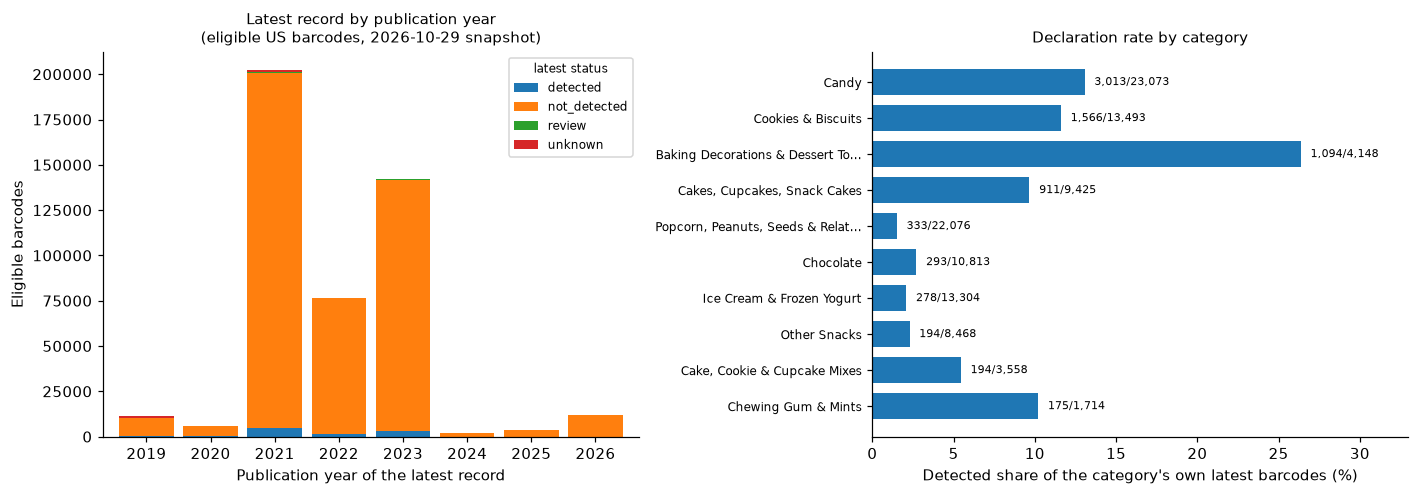

Figure written: record_freshness_and_category.png
Read the left panel as record currency, not shelf presence.


In [21]:
figure_paths = []

if latest["max_date"].notna().any():
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

    ax = axes[0]
    years = latest.assign(year=latest["max_date"].dt.year)
    pivot = (years.dropna(subset=["year"])
             .pivot_table(index="year", columns="latest_declared_status",
                          values="record_count", aggfunc="size")
             .fillna(0).astype(int).sort_index())
    pivot.plot(kind="bar", stacked=True, ax=ax, width=0.85)
    ax.set_title(f"Latest record by publication year\n(eligible US barcodes, "
                 f"{RELEASE_DATE} snapshot)", fontsize=10)
    ax.set_xlabel("Publication year of the latest record")
    ax.set_ylabel("Eligible barcodes")
    ax.legend(title="latest status", fontsize=8, title_fontsize=8)
    ax.tick_params(axis="x", rotation=0)

    ax = axes[1]
    top = category_table.head(10).iloc[::-1]
    bars = ax.barh(range(len(top)), top["percent_of_category"], height=0.72)
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels([c if len(c) <= 32 else c[:31] + "\u2026" for c in top.index],
                       fontsize=8)
    ax.set_xlabel("Detected share of the category's own latest barcodes (%)")
    ax.set_title("Declaration rate by category", fontsize=10)
    for rect, (detected, total) in zip(
            bars, zip(top["latest_gtins_detected"], top["latest_gtins_total"])):
        ax.text(rect.get_width() + 0.6, rect.get_y() + rect.get_height() / 2,
                f"{detected:,}/{total:,}", va="center", fontsize=7.5)
    ax.set_xlim(0, max(float(top["percent_of_category"].max()) * 1.25, 1))

    fig.tight_layout()
    target = FIGURES_DIR / "record_freshness_and_category.png"
    fig.savefig(target, dpi=300, bbox_inches="tight")
    figure_paths.append(str(target.relative_to(RUN_DIR)))
    plt.show()
    print("Figure written:", target.name)
    print("Read the left panel as record currency, not shelf presence.")
else:
    print("No parseable publication dates; figures skipped.")

## 22. Record-Level Human-Review Queues

**Objective:** Construct record-level audit queues for candidate matches, deterministic negative samples (`n = 300`), unresolved GTIN chronologies, and multi-owner/multi-barcode formulation groups.  


**Inputs:** `eligible`, `mentions`, `latest`, `records` | **Outputs:** `candidates`, `negative_sample`, `chronology_queue`, `formulation_queue`, `sampling_design`  


**Methodological Note:** Record-level queues support spot-checking and provenance tracing; Section 23 deduplicates text statements to eliminate redundant annotation labor.


In [22]:
REVIEW_COLUMNS = ["reviewer_id", "reviewer_label", "reviewer_confidence", "reviewer_notes"]

candidates = eligible.loc[eligible["declared_status"].isin(["detected", "review"])].copy()
candidate_context = (mentions.groupby("source_row_number")
                     .agg(name_families=("name_family", lambda s: ",".join(sorted(set(s)))),
                          matched_names=("matched_name", lambda s: " | ".join(s)),
                          any_lake_form=("is_lake_form", "max"),
                          first_before=("before", "first"),
                          first_after=("after", "first"))
                     ) if len(mentions) else pd.DataFrame()
if len(candidate_context):
    candidates = candidates.merge(candidate_context, on="source_row_number", how="left")
for column in REVIEW_COLUMNS:
    candidates[column] = ""

negatives_pool = eligible.loc[eligible["declared_status"].eq("not_detected")]
take = min(NEGATIVE_SAMPLE_SIZE, len(negatives_pool))
negative_sample = (negatives_pool.sort_values("fdc_id", kind="stable")
                   .iloc[rng.choice(len(negatives_pool), size=take, replace=False)]
                   .copy() if take else negatives_pool.copy())
for column in REVIEW_COLUMNS:
    negative_sample[column] = ""

chronology_queue = latest.loc[latest["selection_issue"].ne("")].copy()
detected_variants = set(records.loc[records["declared_status"].eq("detected"),
                                    "exact_variant_id"])
variant_stats = (records.loc[records["exact_variant_id"].isin(detected_variants)]
    .groupby("exact_variant_id")
    .agg(records=("fdc_id", "size"),
         distinct_statuses=("declared_status", lambda s: ",".join(sorted(set(s)))),
         status_count=("declared_status", "nunique"),
         distinct_gtins=("gtin_key", "nunique"),
         owners=("brand_owner_normalized", "nunique")))

reason_parts = pd.DataFrame({
    "mixed status": variant_stats["status_count"] > 1,
    "multiple owners": variant_stats["owners"] > 1,
    "combined across barcodes": variant_stats["distinct_gtins"] > 1,
})
queue_mask = (variant_stats["records"] > 1) & reason_parts.any(axis=1)
formulation_queue = variant_stats.loc[queue_mask].copy()
formulation_queue["review_reasons"] = [
    "; ".join(reason_parts.columns[row]) for row in reason_parts.loc[queue_mask].to_numpy()]
formulation_queue = formulation_queue.sort_values(
    ["records", "distinct_gtins"], ascending=False)
formulation_population = int(len(formulation_queue))
if len(formulation_queue) > FORMULATION_QUEUE_CAP:
    print(f"Formulation queue holds {len(formulation_queue):,} groups; exporting the "
          f"{FORMULATION_QUEUE_CAP:,} largest. Record this cap in the methods section.")
    formulation_queue = formulation_queue.head(FORMULATION_QUEUE_CAP)

sampling_design = pd.DataFrame({
    "queue": ["candidate records", "negative sample", "chronology unresolved",
              "formulation groups"],
    "population": [len(candidates), len(negatives_pool), len(latest), formulation_population],
    "exported": [len(candidates), len(negative_sample), len(chronology_queue),
                 int(len(formulation_queue))],
    "selection": ["all detected or review", f"deterministic random, seed={RANDOM_SEED}",
                  "all unresolved",
                  f"mixed status, multiple owners or combined barcodes; "
                  f"largest {FORMULATION_QUEUE_CAP:,} exported"],
})
display(sampling_design)
print("Blank reviewer columns must be completed by a named reviewer before any "
      "validation claim.")
print("Save completed annotations under:", shown(ANNOTATION_DIR))

Formulation queue holds 541 groups; exporting the 500 largest. Record this cap in the methods section.


,queue,population,exported,selection
0,candidate records,36881,36881,all detected or review
1,negative sample,1921334,300,"deterministic random, seed=42"
2,chronology unresolved,455546,27,all unresolved
3,formulation groups,541,500,"mixed status, multiple owners or combined barcodes; largest 500 exported"


Blank reviewer columns must be completed by a named reviewer before any validation claim.
Save completed annotations under: data/annotations/red3_consolidated


## 23. Unique-Statement Annotation Queue and Stratified Sample

**Objective:** Collapse candidate and sampled negative records to distinct normalized statements (`ingredients_digest`) and draw a design-weighted stratified sample (`annotation_sheet_blind.csv`) for blinded human labeling.  


**Inputs:** `candidates`, `negative_sample`, `audit_file` | **Outputs:** `unique_text_annotation_queue`, `stratified_review_sample`, `annotation_sheet_blind`, `annotation_stratum_design`  


**Methodological Note:** Because `detect_red3` operates on normalized text, records sharing an `ingredients_digest` carry identical system verdicts. Annotators label `annotation_sheet_blind.csv` without seeing `declared_status` or `matched_names`, eliminating anchoring bias.


In [23]:
DETECTED_TEXTS_PER_STRATUM = 150  
ANNOTATION_LABELS = ("declared", "not_declared", "unclear")
ANNOTATION_COLUMNS = ["annotator_1_label", "annotator_2_label",
                      "adjudicated_gold_label", "annotator_notes"]
CONTEXT_COLUMNS = ["name_families", "matched_names", "first_before", "first_after"]


def fetch_ingredient_text(fdc_ids) -> pd.Series:
    """Raw ingredient statements for the given FDC IDs, read from the classified table."""
    wanted = {int(value) for value in fdc_ids}
    parts = []
    if wanted:
        for batch in audit_file.iter_batches(batch_size=BATCH_SIZE,
                                             columns=[COL["fdc_id"], COL["ingredients"]]):
            frame = batch.to_pandas()
            frame = frame.loc[frame[COL["fdc_id"]].isin(wanted)]
            if len(frame):
                parts.append(frame)
    if not parts:
        return pd.Series(dtype="object", name="ingredients")
    found = pd.concat(parts, ignore_index=True)
    text = found[COL["ingredients"]].astype("object")
    text = text.where(text.notna(), "").astype(str)
    text.index = found[COL["fdc_id"]].astype("int64")
    return text.rename("ingredients")

text_record_count = eligible.groupby("ingredients_digest").size()

candidate_frame = candidates.copy()
for column in CONTEXT_COLUMNS:
    if column not in candidate_frame.columns:
        candidate_frame[column] = ""
    values = candidate_frame[column].astype("object")
    candidate_frame[column] = values.where(values.notna(), "").astype(str)

verdicts_per_text = candidate_frame.groupby("ingredients_digest")[
    ["declared_status", "review_reason"]].nunique()
if len(verdicts_per_text) and int(verdicts_per_text.to_numpy().max()) > 1:
    raise AssertionError("Records sharing an ingredients_digest carry different statuses or "
                         "review reasons; the unique-statement queue would be ambiguous.")


def one_row_per_text(frame: pd.DataFrame, queue_name: str) -> pd.DataFrame:
    representatives = (frame.sort_values(["ingredients_digest", "fdc_id"], kind="stable")
                       .drop_duplicates("ingredients_digest", keep="first"))
    table = pd.DataFrame({
        "ingredients_digest": representatives["ingredients_digest"].to_numpy(),
        "record_count": representatives["ingredients_digest"].map(text_record_count)
                        .astype("int64").to_numpy(),
        "declared_status": representatives["declared_status"].to_numpy(),
        "review_reason": representatives["review_reason"].to_numpy(),
    })
    for column in CONTEXT_COLUMNS:
        table[column] = (representatives[column].to_numpy()
                         if column in representatives.columns else "")
    table["representative_fdc_id"] = representatives["fdc_id"].astype("int64").to_numpy()
    table.insert(0, "queue", queue_name)
    return table


candidate_texts = one_row_per_text(candidate_frame, "candidate")
negative_texts = one_row_per_text(negative_sample, "negative_sample")
candidate_texts["records_in_negative_sample"] = 0
negative_texts["records_in_negative_sample"] = (
    negative_texts["ingredients_digest"]
    .map(negative_sample.groupby("ingredients_digest").size()).astype("int64"))
if set(candidate_texts["ingredients_digest"]) & set(negative_texts["ingredients_digest"]):
    raise AssertionError("A statement appears in both the candidate and the negative queue.")

unique_text_annotation_queue = pd.concat([candidate_texts, negative_texts], ignore_index=True)
representative_text = fetch_ingredient_text(unique_text_annotation_queue["representative_fdc_id"])
unique_text_annotation_queue["ingredients"] = (
    unique_text_annotation_queue["representative_fdc_id"].map(representative_text)
    .astype("object").fillna(""))
for column in ANNOTATION_COLUMNS:
    unique_text_annotation_queue[column] = ""
unique_text_annotation_queue = unique_text_annotation_queue[
    ["queue", "ingredients_digest", "record_count", "declared_status", "review_reason",
     *CONTEXT_COLUMNS, "representative_fdc_id", "ingredients",
     "records_in_negative_sample", *ANNOTATION_COLUMNS]
].sort_values(["queue", "record_count", "ingredients_digest"],
              ascending=[True, False, True], kind="stable").reset_index(drop=True)

sample_rng = np.random.default_rng([RANDOM_SEED, 23])
is_candidate = unique_text_annotation_queue["queue"].eq("candidate")
family_label = unique_text_annotation_queue["name_families"].replace("", "(no family)")
unique_text_annotation_queue["sampling_stratum"] = np.select(
    [~is_candidate.to_numpy(),
     unique_text_annotation_queue["declared_status"].eq("review").to_numpy()],
    ["not_detected | negative sample", "review | all statements"],
    default=("detected | " + family_label).to_numpy())

DESIGN_COLUMNS = ["stratum_unit", "stratum_units_total", "stratum_units_sampled",
                  "stratum_records_total", "size_measure", "records_represented"]
sample_parts, design_rows = [], []
for stratum, group in unique_text_annotation_queue.groupby("sampling_stratum", sort=True):
    group = group.sort_values("ingredients_digest", kind="stable")
    if stratum.startswith("detected"):
        take = min(len(group), DETECTED_TEXTS_PER_STRATUM)
        chosen = group.iloc[np.sort(sample_rng.choice(len(group), size=take, replace=False))].copy()
    else:
        chosen = group.copy()
    if stratum.startswith("not_detected"):
 
        unit, units_total, units_sampled = "record", len(negatives_pool), len(negative_sample)
        records_total = len(negatives_pool)
        size = chosen["records_in_negative_sample"].astype("int64")
    else:
    
        unit, units_total, units_sampled = "unique text", len(group), len(chosen)
        records_total = int(group["record_count"].sum())
        size = chosen["record_count"].astype("int64")
    chosen["stratum_unit"] = unit
    chosen["stratum_units_total"] = units_total
    chosen["stratum_units_sampled"] = units_sampled
    chosen["stratum_records_total"] = records_total
    chosen["size_measure"] = size

    chosen["records_represented"] = records_total * size / max(int(size.sum()), 1)
    sample_parts.append(chosen)
    design_rows.append({
        "sampling_stratum": stratum, "sampling_unit": unit,
        "units_in_population": units_total, "units_sampled": units_sampled,
        "sampling_fraction_percent": round(100 * units_sampled / max(units_total, 1), 2),
        "distinct_statements_to_annotate": len(chosen),
        "eligible_records_in_stratum": records_total,
    })

if sample_parts:
    stratified_review_sample = pd.concat(sample_parts, ignore_index=True)
else:
    stratified_review_sample = unique_text_annotation_queue.head(0).assign(
        **{column: [] for column in DESIGN_COLUMNS})
stratified_review_sample = stratified_review_sample.iloc[
    sample_rng.permutation(len(stratified_review_sample))].reset_index(drop=True)
stratified_review_sample.insert(
    0, "sample_id", [f"S{number:05d}" for number in range(1, len(stratified_review_sample) + 1)])
annotation_stratum_design = pd.DataFrame(design_rows, columns=[
    "sampling_stratum", "sampling_unit", "units_in_population", "units_sampled",
    "sampling_fraction_percent", "distinct_statements_to_annotate",
    "eligible_records_in_stratum"])

interpretable_records = int(eligible["declared_status"]
                            .isin(["detected", "review", "not_detected"]).sum())
assert np.isclose(stratified_review_sample["records_represented"].sum(),
                  annotation_stratum_design["eligible_records_in_stratum"].sum()), \
    "Design weights do not sum to the stratum record totals."
assert int(annotation_stratum_design["eligible_records_in_stratum"].sum()) == interpretable_records, \
    "Sampling strata do not partition the interpretable eligible records."

annotation_sheet_blind = stratified_review_sample[
    ["sample_id", "ingredients_digest", "ingredients", *ANNOTATION_COLUMNS]].copy()

candidate_rows = unique_text_annotation_queue["queue"].eq("candidate")
print(f"Candidate records                : {len(candidates):,}")
print(f"Distinct candidate statements    : {int(candidate_rows.sum()):,} "
      f"({len(candidates) / max(int(candidate_rows.sum()), 1):.2f} records per statement)")
print(f"Distinct negative-sample statements: {int((~candidate_rows).sum()):,} "
      f"from {len(negative_sample):,} sampled records")
print(f"Statements to annotate           : {len(stratified_review_sample):,}")
display(annotation_stratum_design)
print("Annotators work from annotation_sheet_blind.csv. Labels:", ", ".join(ANNOTATION_LABELS))
print("Save the merged, adjudicated file under:", shown(ANNOTATION_DIR))

Candidate records                : 36,881
Distinct candidate statements    : 8,858 (4.16 records per statement)
Distinct negative-sample statements: 299 from 300 sampled records
Statements to annotate           : 716


,sampling_stratum,sampling_unit,units_in_population,units_sampled,sampling_fraction_percent,distinct_statements_to_annotate,eligible_records_in_stratum
0,detected | erythrosine,unique text,3,3,100.00,3,9
1,"detected | erythrosine,numeric_red3",unique text,17,17,100.00,17,62
2,detected | numeric_red3,unique text,8591,150,1.75,150,35784
3,not_detected | negative sample,record,1921334,300,0.02,299,1921334
4,review | all statements,unique text,247,247,100.00,247,1026


Annotators work from annotation_sheet_blind.csv. Labels: declared, not_declared, unclear
Save the merged, adjudicated file under: data/annotations/red3_consolidated


## 24. Component Ablation and Routing Funnel

**Objective:** Quantify the contribution of each deterministic NLP component—early-exit filters, Unicode/HTML normalization rescues, review-routing triggers, and package-size stripping—via a read-only pass.  


**Inputs:** `audit_file`, `records`, `latest` | **Outputs:** `nlp_ablation_summary`  


**Methodological Note:** Normalization rescues (`normalization_changed_match`) are attributed to the first sufficient step (`HTML unescaping` → `compatibility folding` → `diacritic removal`). Deduplication compression is evaluated with and without `strip_package_sizes`.


In [24]:
def fast_normalize(text: str) -> str:
    """Exactly normalize(text); plain ASCII without entities takes a short cut."""
    if text.isascii() and "&" not in text:
        return " ".join(text.casefold().split())
    return normalize(text)

assert all(fast_normalize(sample) == normalize(sample) for sample in [
    "", "  SUGAR,\tRED 3 \n", "Sugar\x1fSalt", "FD&C RED NO. 3", "A&amp;B", "Érythrosine",
    "RED ３", "N/A"]), "fast_normalize disagrees with normalize"


def rescue_mechanism(raw: str) -> str:
    """First normalization step that is sufficient for a pattern to match."""
    def matches(text): return bool(FDA_NAMES.search(text) or REVIEW_ALIASES.search(text))
    unescaped = html.unescape(raw)
    if matches(unescaped):
        return "HTML unescaping"
    if matches(unicodedata.normalize("NFKC", unescaped)):
        return "compatibility folding (fullwidth, ligature)"
    stripped = "".join(c for c in unicodedata.normalize("NFKD", unescaped)
                       if not unicodedata.combining(c))
    return "diacritic removal" if matches(stripped) else "other normalization"

has_changed_flag = "normalization_changed_match" in AVAILABLE
pass_columns = [COL["fdc_id"], COL["ingredients"]]
pass_columns += [COL[r] for r in ("description", "match_spans") if r in COL]
pass_columns += ["normalization_changed_match"] if has_changed_flag else []

fdc_parts, placeholder_parts, candidate_parts = [], [], []
description_parts, match_parts, mechanism_counts = [], [], {}
for batch in audit_file.iter_batches(batch_size=BATCH_SIZE, columns=pass_columns):
    frame = batch.to_pandas()
    text = frame[COL["ingredients"]].astype("object")
    text = text.where(text.notna(), "").astype(str)
    normalized = [fast_normalize(value) for value in text]
    fdc_parts.append(frame[COL["fdc_id"]].to_numpy(dtype="int64"))
    placeholder_parts.append(np.fromiter(
        (value in INGREDIENT_PLACEHOLDERS for value in normalized), dtype=bool, count=len(frame)))
    candidate_parts.append(np.fromiter(
        (any(term in value for term in CANDIDATE_SUBSTRINGS) for value in normalized),
        dtype=bool, count=len(frame)))
    if "description" in COL:
        description = frame[COL["description"]].astype("object")
        description = description.where(description.notna(), "").astype(str)
        description_parts.append(np.array([fast_normalize(value) for value in description],
                                          dtype=object))
    if "match_spans" in COL:
        match_parts.append(frame[COL["match_spans"]].astype("object").fillna("[]")
                           .astype(str).ne("[]").to_numpy())
    if has_changed_flag:
        for raw in text[frame["normalization_changed_match"].fillna(False).to_numpy(dtype=bool)]:
            mechanism = rescue_mechanism(raw)
            mechanism_counts[mechanism] = mechanism_counts.get(mechanism, 0) + 1

if not np.array_equal(np.concatenate(fdc_parts), records["fdc_id"].to_numpy()):
    raise AssertionError("Ablation pass is not aligned with the records table.")
is_placeholder = np.concatenate(placeholder_parts)
has_candidate = np.concatenate(candidate_parts)
status = records["declared_status"].to_numpy()
is_match_status = np.isin(status, ["detected", "review"])
has_match = np.concatenate(match_parts) if match_parts else is_match_status
fast_path = ~is_placeholder & ~has_candidate
evaluated = ~is_placeholder & has_candidate


if not np.array_equal(is_placeholder, status == "unknown"):
    raise AssertionError("Placeholder filter and stored `unknown` statuses disagree.")
if not (status[fast_path] == "not_detected").all():
    raise AssertionError("A record without any candidate substring is not `not_detected`.")

ablation_rows = []
def add_row(component, measure, scope, count, denominator=None, denominator_label="", ratio=None):
    ablation_rows.append({
        "component": component, "measure": measure, "scope": scope, "count": int(count),
        "denominator": np.nan if denominator is None else int(denominator),
        "percent": (np.nan if not denominator else round(100 * count / denominator, 4)),
        "denominator_label": denominator_label,
        "ratio": np.nan if ratio is None else round(float(ratio), 4),
    })

total = len(records)
ALL = "all source records"
add_row("routing funnel", "source records", ALL, total)
add_row("routing funnel", "exit: placeholder or missing statement -> unknown", ALL,
        is_placeholder.sum(), total, "source records")
add_row("routing funnel", "exit: no candidate substring (fast path) -> not_detected", ALL,
        fast_path.sum(), total, "source records")
add_row("routing funnel", "evaluated by the patterns", ALL, evaluated.sum(), total, "source records")
for outcome in ("detected", "review", "not_detected"):
    add_row("routing funnel", f"evaluated -> {outcome}", ALL,
            (evaluated & (status == outcome)).sum(), evaluated.sum(), "records evaluated by the patterns")

matched_total = int(has_match.sum())
rescued_total = int(sum(mechanism_counts.values()))
add_row("normalization", "records with at least one pattern match", ALL, matched_total)
if has_changed_flag:
    add_row("normalization", "match exists only after normalization", ALL,
            rescued_total, matched_total, "records with a match")
    for mechanism in ("HTML unescaping", "compatibility folding (fullwidth, ligature)",
                      "diacritic removal", "other normalization"):
        add_row("normalization", f"rescued by: {mechanism}", ALL,
                mechanism_counts.get(mechanism, 0), matched_total, "records with a match")
else:
    print("normalization_changed_match is not in this classified table; set "
          "REBUILD_AUDIT = True to measure the normalization rescue.")

review_reasons = records.loc[status == "review", "review_reason"].astype(str)
review_total = len(review_reasons)
add_row("review routing", "records routed to review", ALL, review_total,
        int(is_match_status.sum()), "detected or review records")
single_reasons = review_reasons.str.split(";").explode()
single_reasons = single_reasons[single_reasons.ne("")]
for reason, count in single_reasons.value_counts().items():
    add_row("review routing", f"reason present: {reason}", ALL, count, review_total,
            "review records (reasons can co-occur)")
for combination, count in review_reasons.value_counts().items():
    label = combination.replace(";", " + ") if combination else "(no reason recorded)"
    add_row("review routing", f"exact combination: {label}", ALL, count, review_total,
            "review records (combinations are exclusive)")
for issue, count in latest.loc[latest["selection_issue"].ne(""), "selection_issue"].value_counts().items():
    add_row("review routing", f"latest barcode held for review: {issue}",
            "eligible latest barcodes", count, len(latest), "eligible latest barcodes")

keys = pd.DataFrame({
    "owner": records["brand_owner_normalized"].to_numpy(),
    "brand": records["brand_name_normalized"].to_numpy(),
    "subbrand": records["subbrand_name_normalized"].to_numpy(),
    "description_stripped": records["description_without_package_size"].to_numpy(),
    "description_full": (np.concatenate(description_parts) if description_parts
                         else records["description_without_package_size"].to_numpy()),
    "ingredients_digest": records["ingredients_digest"].to_numpy(),
    # Records with insufficient identity never merge: give each its own key.
    "unresolved": np.where(records["insufficient_variant_identity"].to_numpy(),
                           records["source_row_number"].astype(str).to_numpy(), ""),
})
def distinct(frame, columns): return int(len(frame[columns].drop_duplicates()))
IDENTITY = ["owner", "brand", "subbrand"]

for scope, mask in [(ALL, np.ones(total, dtype=bool)),
                    ("detected or review records", is_match_status)]:
    subset, n = keys.loc[mask], int(mask.sum())
    identities_full = distinct(subset, IDENTITY + ["description_full"])
    identities_stripped = distinct(subset, IDENTITY + ["description_stripped"])
    variants_full = distinct(subset, IDENTITY + ["description_full", "ingredients_digest", "unresolved"])
    variants_stripped = distinct(subset, IDENTITY + ["description_stripped", "ingredients_digest", "unresolved"])
    if scope == ALL:
        assert identities_stripped == records["identity_id"].nunique(), "identity keys diverge"
        assert variants_stripped == records["exact_variant_id"].nunique(), "variant keys diverge"
    add_row("deduplication", "records", scope, n)
    add_row("deduplication", "records where a package-size span was removed", scope,
            records.loc[mask, "removed_package_size_spans"].ne("[]").sum(), n, "records in scope")
    for label, units in [
            ("product identities, sizes NOT stripped", identities_full),
            ("product identities, sizes stripped (identity_id)", identities_stripped),
            ("exact variants, sizes NOT stripped", variants_full),
            ("exact variants, sizes stripped (exact_variant_id)", variants_stripped)]:
        add_row("deduplication", label, scope, units, n, "records in scope",
                ratio=n / max(units, 1))
    add_row("deduplication", "identities merged by size stripping alone", scope,
            identities_full - identities_stripped, identities_full,
            "identities before stripping")
    add_row("deduplication", "exact variants merged by size stripping alone", scope,
            variants_full - variants_stripped, variants_full, "variants before stripping")

nlp_ablation_summary = pd.DataFrame(ablation_rows)
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 70):
    display(nlp_ablation_summary)
print("`ratio` is records per unit. Every percentage is relative to `denominator_label`.")
del keys

,component,measure,scope,count,denominator,percent,denominator_label,ratio
0,routing funnel,source records,all source records,2010212,NaN,NaN,,NaN
1,routing funnel,exit: placeholder or missing statement -> unknown,all source records,5374,2010212.0,0.2673,source records,NaN
2,routing funnel,exit: no candidate substring (fast path) -> not_detected,all source records,1165852,2010212.0,57.9965,source records,NaN
3,routing funnel,evaluated by the patterns,all source records,838986,2010212.0,41.7362,source records,NaN
4,routing funnel,evaluated -> detected,all source records,36047,838986.0,4.2965,records evaluated by the patterns,NaN
5,routing funnel,evaluated -> review,all source records,1035,838986.0,0.1234,records evaluated by the patterns,NaN
6,routing funnel,evaluated -> not_detected,all source records,801904,838986.0,95.5801,records evaluated by the patterns,NaN
7,normalization,records with at least one pattern match,all source records,37082,NaN,NaN,,NaN
8,normalization,match exists only after normalization,all source records,0,37082.0,0.0000,records with a match,NaN
9,normalization,rescued by: HTML unescaping,all source records,0,37082.0,0.0000,records with a match,NaN


`ratio` is records per unit. Every percentage is relative to `denominator_label`.


## 25. Structural Position and Sub-Component Parsing

**Objective:** Parse balanced parenthetical nesting and top-level ingredient order to separate primary-matrix declarations from parenthetical color groups (`ARTIFICIAL COLORS (RED 3)`) and composite sub-components (`SPRINKLES (SUGAR, RED 3)`).  

**Inputs:** `mentions`, `audit_file`, `candidates` | **Outputs:** `ingredient_position_summary`  


**Methodological Note:** Statements are evaluated once per unique `ingredients_digest`. Matches appearing after 21 CFR 101.4(a)(2) minor-ingredient clauses (*"2% or less of"*) are flagged separately because descending-weight ordering does not apply within that tail clause.


In [25]:
OPENERS, CLOSERS, TOP_LEVEL_SEPARATORS = "([{", ")]}", ",;"
HEAD_STOPS = ",;:.([{)]}"
COLOUR_GROUP_HEAD = re.compile(r"\bcolou?r(?:s|ed|ing|ings)?\b|\bdyes?\b|\bfd\s*&\s*c\b", re.I)
MINOR_CLAUSE = re.compile(
    r"less\s+than\s+\d+(?:\.\d+)?\s*(?:%|percent)|\d+(?:\.\d+)?\s*(?:%|percent)\s+or\s+less", re.I)
PLACEMENTS = ["top level", "colour group", "sub-component"]
TOP_CATEGORIES_SHOWN = 8


def locate_in_statement(text: str, starts) -> tuple:
    """For each match start: the brackets open around it. Also the top-level segments."""
    wanted, open_brackets, boundaries, stray_closers, found = set(starts), [], [], 0, {}
    # The semicolon that ends an HTML entity (`FD&amp;C`) is not an ingredient separator.
    entity_semicolons = ({m.end() - 1 for m in _ENTITY.finditer(text)
                          if html.unescape(m.group(0)) != m.group(0)} if "&" in text else set())
    for position, character in enumerate(text):
        if position in wanted:
            found[position] = tuple(open_brackets)
        if character in OPENERS:
            open_brackets.append(position)
        elif character in CLOSERS:
            if open_brackets:
                open_brackets.pop()
            else:
                stray_closers += 1
        elif (character in TOP_LEVEL_SEPARATORS and not open_brackets
              and position not in entity_semicolons):
            boundaries.append(position)
    balanced = not open_brackets and stray_closers == 0
    edges = [-1, *boundaries, len(text)]
    segments = [(edges[k] + 1, edges[k + 1]) for k in range(len(edges) - 1)]
    segments = [(a, b) for a, b in segments if any(ch.isalnum() for ch in text[a:b])]
    return found, segments, balanced


def bracket_head(text: str, opener: int) -> str:
    """The words immediately heading a bracket: `SPRINKLES` in `SPRINKLES (SUGAR, ...)`."""
    begin = opener
    while begin > 0 and text[begin - 1] not in HEAD_STOPS:
        begin -= 1
    return text[begin:opener].strip()

_demo = "FLOUR (WHEAT, NIACIN), SPRINKLES (SUGAR, RED 3), COLORS (RED 3, BLUE 1), SALT."
_found, _segments, _balanced = locate_in_statement(_demo, [_demo.index("RED 3"), _demo.rindex("RED 3")])
assert _balanced and len(_segments) == 4
assert [bracket_head(_demo, p) for p in _found[_demo.index("RED 3")]] == ["SPRINKLES"]
assert [bracket_head(_demo, p) for p in _found[_demo.rindex("RED 3")]] == ["COLORS"]
assert not locate_in_statement("SUGAR, SPRINKLES (SUGAR, RED 3", [0])[2]
assert len(locate_in_statement("SUGAR, FD&amp;C RED NO. 3, SALT.", [7])[1]) == 3
assert len(locate_in_statement("SUGAR; SALT; RED 3", [13])[1]) == 3

POSITION_COLUMNS = ["is_parenthetical_subingredient", "parenthetical_context",
                    "top_level_ingredient_head", "top_level_ingredient_index",
                    "total_top_level_ingredients", "relative_ingredient_position",
                    "after_minor_ingredient_clause", "brackets_balanced"]

if len(mentions):
    row_to_fdc = records.set_index("source_row_number")["fdc_id"]
    mention_text = fetch_ingredient_text(mentions["source_row_number"].map(row_to_fdc).unique())
    located, offset_mismatches = {}, 0
    for row_number, group in mentions.groupby("source_row_number", sort=False):
        text = mention_text.get(int(row_to_fdc.loc[row_number]), "")
        found, segments, balanced = locate_in_statement(text, group["start"].tolist())
        clause = MINOR_CLAUSE.search(text)
        for index, start, end, matched in zip(group.index, group["start"], group["end"],
                                              group["matched_name"]):
            offset_mismatches += text[start:end] != matched
            enclosing = found.get(start, ())
            heads = [bracket_head(text, opener) for opener in enclosing]
            named = [head for head in heads if head]
            if not enclosing:
                context = "top level"
            elif named and all(COLOUR_GROUP_HEAD.search(head) for head in named):
                context = "colour group"
            else:
                context = "sub-component"
            position = next((k for k, (a, b) in enumerate(segments, start=1) if a <= start < b), None)
            segment_text = text[segments[position - 1][0]:segments[position - 1][1]] if position else ""
            head = re.split(r"[(\[{]", segment_text, maxsplit=1)[0].strip()[:60]
            located[index] = (bool(enclosing), context, head,
                              position if position else np.nan, len(segments),
                              (position / len(segments)) if position else np.nan,
                              bool(clause and clause.start() < start), balanced)
    if offset_mismatches:
        raise AssertionError(f"{offset_mismatches} match offsets do not index the stored text.")
    position_frame = pd.DataFrame.from_dict(located, orient="index", columns=POSITION_COLUMNS)
    mentions = mentions.drop(columns=[c for c in POSITION_COLUMNS if c in mentions.columns])
    mentions = mentions.join(position_frame)
else:
    for column in POSITION_COLUMNS:
        mentions[column] = pd.Series(dtype="object")
SUMMARY_COLUMNS = ["grouping", "group", "placement", "mentions", "statements",
                   "share_of_group_percent", "mean_relative_position",
                   "median_relative_position", "after_minor_clause_percent"]
representative_rows = set(candidates.sort_values(["ingredients_digest", "fdc_id"], kind="stable")
                          .drop_duplicates("ingredients_digest")["source_row_number"])
statement_mentions = mentions.loc[mentions["source_row_number"].isin(representative_rows)].copy()
unbalanced_mentions = int((~statement_mentions["brackets_balanced"].astype(bool)).sum()) \
    if len(statement_mentions) else 0
statement_mentions = statement_mentions.loc[statement_mentions["brackets_balanced"].astype(bool)] \
    if len(statement_mentions) else statement_mentions
statement_mentions["category"] = statement_mentions["source_row_number"].map(
    records.set_index("source_row_number")["category"])
statement_mentions["dye_form"] = np.where(statement_mentions["is_lake_form"].astype(bool),
                                          "lake", "base")

def summarise_placement(frame: pd.DataFrame, grouping: str, group: str) -> list:
    rows = []
    for placement, part in [("all placements", frame),
                            *[(name, frame.loc[frame["parenthetical_context"].eq(name)])
                              for name in PLACEMENTS]]:
        if not len(part):
            continue
        relative = part["relative_ingredient_position"].astype(float)
        rows.append({
            "grouping": grouping, "group": group, "placement": placement,
            "mentions": len(part), "statements": int(part["source_row_number"].nunique()),
            "share_of_group_percent": round(100 * len(part) / len(frame), 2),
            "mean_relative_position": round(float(relative.mean()), 3),
            "median_relative_position": round(float(relative.median()), 3),
            "after_minor_clause_percent": round(
                100 * float(part["after_minor_ingredient_clause"].astype(bool).mean()), 2),
        })
    return rows

position_rows = []
if len(statement_mentions):
    position_rows += summarise_placement(statement_mentions, "overall", "all distinct statements")
    for form, part in statement_mentions.groupby("dye_form", sort=True):
        position_rows += summarise_placement(part, "dye form", form)
    top_categories = (statement_mentions.groupby("category")["source_row_number"].nunique()
                      .sort_values(ascending=False).head(TOP_CATEGORIES_SHOWN).index)
    for category in top_categories:
        position_rows += summarise_placement(
            statement_mentions.loc[statement_mentions["category"].eq(category)],
            "category", category)
ingredient_position_summary = pd.DataFrame(position_rows, columns=SUMMARY_COLUMNS)

if len(statement_mentions):
    counts = statement_mentions["parenthetical_context"].value_counts()
    total_mentions = len(statement_mentions)
    print(f"Distinct candidate statements analysed : "
          f"{statement_mentions['source_row_number'].nunique():,} ({total_mentions:,} matches)")
    for name in PLACEMENTS:
        print(f"  {name:14s}: {int(counts.get(name, 0)):>7,} "
              f"({100 * counts.get(name, 0) / total_mentions:.2f}%)")
    print(f"Matches excluded for unbalanced brackets: {unbalanced_mentions:,}")
    print(f"Matches after a minor-ingredient clause : "
          f"{100 * statement_mentions['after_minor_ingredient_clause'].astype(bool).mean():.2f}%")
    with pd.option_context("display.max_rows", 120):
        display(ingredient_position_summary)
    print("Only `sub-component` indicates a composite product. `colour group` is a class "
          "name with its members, declared for the food itself.")
else:
    print("No candidate matches; position analysis is empty for this input.")

Distinct candidate statements analysed : 8,299 (9,038 matches)
  top level     :   4,795 (53.05%)
  colour group  :   2,301 (25.46%)
  sub-component :   1,942 (21.49%)
Matches excluded for unbalanced brackets: 681
Matches after a minor-ingredient clause : 25.99%


,grouping,group,placement,mentions,statements,share_of_group_percent,mean_relative_position,median_relative_position,after_minor_clause_percent
0,overall,all distinct statements,all placements,9038,8299,100.00,0.781,0.846,25.99
1,overall,all distinct statements,top level,4795,4446,53.05,0.799,0.833,27.67
2,overall,all distinct statements,colour group,2301,2218,25.46,0.859,0.952,27.68
3,overall,all distinct statements,sub-component,1942,1774,21.49,0.643,0.667,19.82
4,dye form,base,all placements,8082,7430,100.00,0.788,0.857,23.58
5,dye form,base,top level,4318,4004,53.43,0.805,0.846,25.27
6,dye form,base,colour group,1985,1913,24.56,0.876,1.000,23.48
7,dye form,base,sub-component,1779,1637,22.01,0.649,0.667,19.62
8,dye form,lake,all placements,956,944,100.00,0.718,0.750,46.34
9,dye form,lake,top level,477,473,49.90,0.744,0.750,49.48


Only `sub-component` indicates a composite product. `colour group` is a class name with its members, declared for the food itself.


## 26. Gold-Standard Evaluation and Benchmark Export

**Objective:** Compute inter-annotator agreement (Cohen's κ) and population-weighted Precision, Recall, and F1 (with 95% Wilson intervals) once completed human labels are placed in `data/annotations/red3_consolidated/`, and export `gold_standard_benchmark.parquet`.  


**Inputs:** Completed CSVs in `ANNOTATION_DIR` | **Outputs:** `annotation_agreement`, `gold_stratum_estimates`, `gold_evaluation_summary`, `processed/gold_standard_benchmark.parquet`, `adjudication_log` (statements the two annotators labelled differently), `human_validation_complete` flag  


**Methodological Note:** Stratum estimates are scaled to eligible U.S. record totals using Kish effective sample sizes. Statement-level SHA-256 hashing assigns `dev` (`20%`) and `test` (`80%`) splits with zero text overlap for downstream LLM benchmarking.


In [26]:
BENCHMARK_DEV_FRACTION = 0.20
REQUIRED_ANNOTATION_COLUMNS = {"ingredients_digest", "adjudicated_gold_label"}
LABEL_COLUMNS = ["annotator_1_label", "annotator_2_label", "adjudicated_gold_label"]
Z95 = 1.959963984540054

AGREEMENT_COLUMNS = ["scope", "double_annotated_statements", "raw_agreement_percent", "cohen_kappa"]
STRATUM_COLUMNS = ["sampling_stratum", "declared_status", "sampling_unit", "statements_annotated",
                   "statements_unclear", "effective_sample_size", "fully_enumerated",
                   "declared_share", "declared_share_lower_95", "declared_share_upper_95",
                   "eligible_records_in_stratum", "estimated_declared_records"]
EVALUATION_COLUMNS = ["operating_point", "metric", "estimate", "lower_95", "upper_95"]
ADJUDICATION_COLUMNS = ["sample_id", "ingredients_digest", "sampling_stratum", "declared_status",
                        "annotator_1_label", "annotator_2_label", "adjudicated_gold_label",
                        "annotator_notes", "adjudication_reason", "ingredients"]


def clean_label(value) -> str:
    return re.sub(r"[\s\-]+", "_", ("" if value is None else str(value)).strip().casefold())


def wilson_interval(successes: float, trials: float) -> tuple:
    if not trials or trials <= 0:
        return (np.nan, np.nan)
    p = successes / trials
    scale = 1 + Z95 ** 2 / trials
    centre = (p + Z95 ** 2 / (2 * trials)) / scale
    half = Z95 * np.sqrt(p * (1 - p) / trials + Z95 ** 2 / (4 * trials ** 2)) / scale
    return (max(0.0, centre - half), min(1.0, centre + half))


def cohen_kappa(first: pd.Series, second: pd.Series) -> tuple:
    """(raw agreement, kappa). Kappa is undefined when chance agreement is total."""
    observed = float((first.to_numpy() == second.to_numpy()).mean())
    labels = set(first) | set(second)
    expected = sum(float((first == label).mean()) * float((second == label).mean())
                   for label in labels)
    return observed, (np.nan if np.isclose(expected, 1.0) else (observed - expected) / (1 - expected))


def evaluate_human_annotations() -> dict:
    outcome = {
        "complete": False,
        "status": {"state": "no annotation files", "annotation_files": [],
                   "sample_statements": int(len(stratified_review_sample)),
                   "statements_with_gold_label": 0, "coverage_percent": 0.0,
                   "double_annotated_statements": 0, "benchmark": None},
        "agreement": pd.DataFrame(columns=AGREEMENT_COLUMNS),
        "strata": pd.DataFrame(columns=STRATUM_COLUMNS),
        "summary": pd.DataFrame(columns=EVALUATION_COLUMNS),
        "adjudication_log": pd.DataFrame(columns=ADJUDICATION_COLUMNS),
    }
    status = outcome["status"]

    frames = []
    for path in (sorted(ANNOTATION_DIR.glob("*.csv")) if ANNOTATION_DIR.is_dir() else []):
        try:
            frame = pd.read_csv(path, dtype=str, keep_default_na=False, encoding="utf-8-sig")
        except Exception as error:
            print(f"Skipping {path.name}: {type(error).__name__}: {error}")
            continue
        if REQUIRED_ANNOTATION_COLUMNS.issubset(frame.columns):
            frames.append(frame.assign(annotation_file=path.name))
            status["annotation_files"].append(path.name)
    if not frames:
        print("No completed annotation file found in", shown(ANNOTATION_DIR))
        print("Annotate tables/annotation_sheet_blind.csv from this run, then save the merged "
              "file there with the columns:", ", ".join(["ingredients_digest", *LABEL_COLUMNS]))
        print("human_validation_complete stays False.")
        return outcome

    annotations = pd.concat(frames, ignore_index=True)
    for column in LABEL_COLUMNS:
        if column not in annotations.columns:
            annotations[column] = ""
        annotations[column] = annotations[column].map(clean_label)
    sample_digests = set(stratified_review_sample["ingredients_digest"])
    outside = int((~annotations["ingredients_digest"].isin(sample_digests)).sum())
    annotations = annotations.loc[annotations["ingredients_digest"].isin(sample_digests)]
    unrecognised = annotations.loc[~annotations["adjudicated_gold_label"]
                                   .isin([*ANNOTATION_LABELS, ""]), "adjudicated_gold_label"]
    gold_rows = annotations.loc[annotations["adjudicated_gold_label"].isin(ANNOTATION_LABELS)]
    if outside:
        print(f"Ignored {outside:,} annotated row(s) for statements outside this run's sample.")
    if len(unrecognised):
        print(f"Ignored {len(unrecognised):,} gold label(s) outside {ANNOTATION_LABELS}: "
              + ", ".join(sorted(set(unrecognised))[:8]))

    conflicting = gold_rows.groupby("ingredients_digest")["adjudicated_gold_label"].nunique()
    conflicting = conflicting[conflicting > 1]
    if len(conflicting):
        status["state"] = "conflicting gold labels"
        print(f"{len(conflicting):,} statement(s) carry more than one adjudicated label. "
              "Resolve these and rerun; human_validation_complete stays False.")
        display(gold_rows.loc[gold_rows["ingredients_digest"].isin(conflicting.index),
                              ["ingredients_digest", "adjudicated_gold_label", "annotation_file"]]
                .sort_values("ingredients_digest").head(20))
        return outcome

    gold = gold_rows.drop_duplicates("ingredients_digest").set_index("ingredients_digest")[
        [*LABEL_COLUMNS, "annotation_file"]]
    labelled = (stratified_review_sample.drop(columns=ANNOTATION_COLUMNS)
                .merge(gold, left_on="ingredients_digest", right_index=True, how="left"))
    has_gold = labelled["adjudicated_gold_label"].notna()
    status["statements_with_gold_label"] = int(has_gold.sum())
    status["coverage_percent"] = round(100 * float(has_gold.mean()), 2) if len(labelled) else 0.0

    if not len(labelled) or not has_gold.all():
        status["state"] = "annotation incomplete"
        print(f"Annotation in progress: {int(has_gold.sum()):,} of {len(labelled):,} sampled "
              f"statements have an adjudicated gold label ({status['coverage_percent']}%).")
        display(labelled.assign(labelled=has_gold).groupby("sampling_stratum")["labelled"]
                .agg(statements="size", with_gold_label="sum"))
        print("Metrics are not computed on a partial sample. human_validation_complete stays False.")
        return outcome

    both = labelled.loc[labelled["annotator_1_label"].isin(ANNOTATION_LABELS)
                        & labelled["annotator_2_label"].isin(ANNOTATION_LABELS)]
    status["double_annotated_statements"] = int(len(both))
    agreement_rows = []
    for scope, part in [("all double-annotated statements", both),
                        *[(f"detector status: {name}", group)
                          for name, group in both.groupby("declared_status", sort=True)]]:
        if len(part):
            observed, kappa = cohen_kappa(part["annotator_1_label"], part["annotator_2_label"])
            agreement_rows.append({"scope": scope, "double_annotated_statements": len(part),
                                   "raw_agreement_percent": round(100 * observed, 2),
                                   "cohen_kappa": (np.nan if np.isnan(kappa) else round(kappa, 4))})
    outcome["agreement"] = pd.DataFrame(agreement_rows, columns=AGREEMENT_COLUMNS)
    if not len(both):
        print("WARNING: no statement carries both annotator labels, so agreement cannot be "
              "reported. A gold standard without measured agreement is hard to defend.")

 
    disputed = both.loc[both["annotator_1_label"].ne(both["annotator_2_label"])].copy()
    first_rows = gold_rows.drop_duplicates("ingredients_digest").set_index("ingredients_digest")
    for column in ("annotator_notes", "adjudication_reason"):   # optional free-text columns
        disputed[column] = (disputed["ingredients_digest"].map(first_rows[column])
                            if column in first_rows.columns else "")
    outcome["adjudication_log"] = (disputed.reindex(columns=ADJUDICATION_COLUMNS).fillna("")
                                   .sort_values(["sampling_stratum", "ingredients_digest"])
                                   .reset_index(drop=True))
    status["annotator_disagreements"] = int(len(disputed))

    stratum_rows = []
    for stratum, group in labelled.groupby("sampling_stratum", sort=True):
        definite = group.loc[group["adjudicated_gold_label"].ne("unclear")]
        size = definite["size_measure"].astype(float)
        declared = definite["adjudicated_gold_label"].eq("declared")
        weight = float(size.sum())
        share = float((size * declared).sum() / weight) if weight else np.nan
        unit = group["stratum_unit"].iloc[0]

        effective = weight if unit == "record" else (weight ** 2 / float((size ** 2).sum()) if weight else 0.0)
        enumerated = bool(group["stratum_units_sampled"].iloc[0] == group["stratum_units_total"].iloc[0])
        if enumerated:
    
            everything = float(group["size_measure"].astype(float).sum())
            declared_weight = float((size * declared).sum())
            lower, upper = declared_weight / everything, (declared_weight + everything - weight) / everything
        else:
            lower, upper = wilson_interval(share * effective, effective)
        records_total = int(group["stratum_records_total"].iloc[0])
        stratum_rows.append({
            "sampling_stratum": stratum, "declared_status": group["declared_status"].iloc[0],
            "sampling_unit": unit, "statements_annotated": len(group),
            "statements_unclear": int(len(group) - len(definite)),
            "effective_sample_size": round(effective, 2), "fully_enumerated": enumerated,
            "declared_share": share, "declared_share_lower_95": lower,
            "declared_share_upper_95": upper, "eligible_records_in_stratum": records_total,
            "estimated_declared_records": share * records_total,
        })
    strata = pd.DataFrame(stratum_rows, columns=STRATUM_COLUMNS)
    outcome["strata"] = strata
    if strata["declared_share"].isna().any():
        status["state"] = "a stratum has no definite gold label"
        print("At least one stratum has only `unclear` labels, so it cannot be scaled. "
              "human_validation_complete stays False.")
        display(strata)
        return outcome

    def declared_records(statuses) -> np.ndarray:
        """Estimated truly-declared records in these strata: [estimate, lower, upper]."""
        part = strata.loc[strata["declared_status"].isin(statuses)]
        total = part["eligible_records_in_stratum"].astype(float)
        return np.array([(total * part[column].astype(float)).sum() for column in
                         ("declared_share", "declared_share_lower_95", "declared_share_upper_95")])

    def records_in(statuses) -> float:
        return float(strata.loc[strata["declared_status"].isin(statuses),
                                "eligible_records_in_stratum"].sum())

    in_detected, in_review, in_negative = (declared_records([s]) for s in
                                           ("detected", "review", "not_detected"))
    detected_total, review_total = records_in(["detected"]), records_in(["review"])
    operating_points = {
        "strict (detected only)":
            (in_detected, in_review + in_negative, np.full(3, detected_total)),
        "flag-all (detected or review)":
            (in_detected + in_review, in_negative, np.full(3, detected_total + review_total)),
        "human-in-the-loop (detected + adjudicated review)":
            (in_detected + in_review, in_negative, detected_total + in_review),
    }
    def safe(numerator, denominator): return numerator / denominator if denominator else np.nan
    def f1(precision, recall):
        return safe(2 * precision * recall, precision + recall) if not np.isnan(precision + recall) else np.nan

    summary_rows = []
    for name, (true_positive, false_negative, called_positive) in operating_points.items():
        precision = [safe(true_positive[k], called_positive[k]) for k in range(3)]
        recall = [safe(true_positive[0], true_positive[0] + false_negative[0]),
                  safe(true_positive[1], true_positive[1] + false_negative[2]),
                  safe(true_positive[2], true_positive[2] + false_negative[1])]
        for metric, values in [("precision", precision), ("recall", recall),
                               ("f1", [f1(precision[k], recall[k]) for k in range(3)])]:
            summary_rows.append({"operating_point": name, "metric": metric, "estimate": values[0],
                                 "lower_95": values[1], "upper_95": values[2]})
        for metric, values in [
                ("estimated true-positive records", true_positive),
                ("estimated false-positive records", (called_positive - true_positive)[[0, 2, 1]]),
                ("estimated false-negative records", false_negative)]:
            summary_rows.append({"operating_point": name, "metric": metric, "estimate": values[0],
                                 "lower_95": min(values[1], values[2]),
                                 "upper_95": max(values[1], values[2])})
    all_declared = in_detected + in_review + in_negative
    interpretable_total = float(strata["eligible_records_in_stratum"].sum())
    summary_rows.append({"operating_point": "population", "metric": "estimated declared records",
                         "estimate": all_declared[0], "lower_95": all_declared[1],
                         "upper_95": all_declared[2]})
    summary_rows.append({"operating_point": "population",
                         "metric": "estimated declared share of interpretable eligible records",
                         "estimate": safe(all_declared[0], interpretable_total),
                         "lower_95": safe(all_declared[1], interpretable_total),
                         "upper_95": safe(all_declared[2], interpretable_total)})
    outcome["summary"] = pd.DataFrame(summary_rows, columns=EVALUATION_COLUMNS)

    gold_columns = labelled.set_index("ingredients_digest")[
        ["adjudicated_gold_label", "sampling_stratum", "records_represented"]]
    benchmark = records.loc[records["ingredients_digest"].isin(gold_columns.index),
                            ["fdc_id", "gtin_key", "ingredients_digest", "declared_status",
                             "review_reason", "is_us_market", "gtin_syntax_valid"]].copy()
    benchmark["in_eligible_cohort"] = benchmark.pop("is_us_market") & benchmark.pop("gtin_syntax_valid")
    benchmark = benchmark.join(gold_columns, on="ingredients_digest")
    benchmark["ingredients"] = benchmark["fdc_id"].map(
        fetch_ingredient_text(benchmark["fdc_id"])).astype("object").fillna("")
    benchmark["split"] = benchmark["ingredients_digest"].map(
        lambda digest: "dev" if int(hashlib.sha256(
            f"{RANDOM_SEED}:{digest}".encode("utf-8")).hexdigest()[:8], 16) / 0xFFFFFFFF
        < BENCHMARK_DEV_FRACTION else "test")
    benchmark = benchmark[["fdc_id", "gtin_key", "ingredients_digest", "ingredients",
                           "declared_status", "review_reason", "adjudicated_gold_label", "split",
                           "sampling_stratum", "records_represented", "in_eligible_cohort"]]
    benchmark_path = RESULT_DIR / "gold_standard_benchmark.parquet"
    benchmark.to_parquet(benchmark_path, index=False)
    assert len(pd.read_parquet(benchmark_path, columns=["fdc_id"])) == len(benchmark)

    outcome["complete"] = True
    status.update({"state": "complete", "benchmark": str(benchmark_path.relative_to(RUN_DIR)),
                   "benchmark_records": int(len(benchmark)),
                   "benchmark_statements": int(benchmark["ingredients_digest"].nunique()),
                   "benchmark_records_by_split": {
                       name: int(count) for name, count in
                       benchmark["split"].value_counts().sort_index().items()}})

    print(f"Gold labels cover all {len(labelled):,} sampled statements "
          f"({int(len(both)):,} double-annotated).")
    display(outcome["agreement"])
    display(strata)
    display(outcome["summary"])
    display(benchmark.drop_duplicates("ingredients_digest")
            .groupby(["split", "adjudicated_gold_label"]).size().unstack(fill_value=0))
    if len(outcome["adjudication_log"]):
        print(f"Annotators disagreed on {len(outcome['adjudication_log']):,} statement(s). To record why "
              "each was resolved as it was, add an `adjudication_reason` column to the annotation "
              "file for these statements; it is carried into tables/adjudication_log.csv.")
        display(outcome["adjudication_log"].drop(columns=["ingredients"]))
    print(f"Benchmark written: {shown(benchmark_path)} ({len(benchmark):,} records for "
          f"{benchmark['ingredients_digest'].nunique():,} statements; by split: "
          f"{status['benchmark_records_by_split']})")
    print("Rates are weighted to eligible records. Intervals combine per-stratum 95% Wilson "
          "bounds conservatively; the recall interval is governed by the negative sample.")
    return outcome


evaluation = evaluate_human_annotations()
human_validation_complete = bool(evaluation["complete"])
validation_status = evaluation["status"]
annotation_agreement = evaluation["agreement"]
gold_stratum_estimates = evaluation["strata"]
gold_evaluation_summary = evaluation["summary"]
adjudication_log = evaluation["adjudication_log"]
print("\nhuman_validation_complete =", human_validation_complete,
      "| state:", validation_status["state"])

Gold labels cover all 716 sampled statements (716 double-annotated).


,scope,double_annotated_statements,raw_agreement_percent,cohen_kappa
0,all double-annotated statements,716,99.58,0.9915
1,detector status: detected,170,100.00,NaN
2,detector status: not_detected,299,99.67,0.0000
3,detector status: review,247,99.19,0.5971


,sampling_stratum,declared_status,sampling_unit,statements_annotated,statements_unclear,effective_sample_size,fully_enumerated,declared_share,declared_share_lower_95,declared_share_upper_95,eligible_records_in_stratum,estimated_declared_records
0,detected | erythrosine,detected,unique text,3,0,2.45,True,1.000000,1.000000e+00,1.000000,9,9.000000
1,"detected | erythrosine,numeric_red3",detected,unique text,17,0,14.45,True,1.000000,1.000000e+00,1.000000,62,62.000000
2,detected | numeric_red3,detected,unique text,150,0,65.56,False,1.000000,9.446486e-01,1.000000,35784,35784.000000
3,not_detected | negative sample,not_detected,record,299,0,300.00,False,0.000000,8.673617e-19,0.012643,1921334,0.000000
4,review | all statements,review,unique text,247,1,164.54,True,0.996086,9.922027e-01,0.996101,1026,1021.984344


,operating_point,metric,estimate,lower_95,upper_95
0,strict (detected only),precision,1.000000,9.447582e-01,1.000000
1,strict (detected only),recall,0.972287,5.723203e-01,0.972392
2,strict (detected only),f1,0.985949,7.128231e-01,0.986003
3,strict (detected only),estimated true-positive records,35855.000000,3.387431e+04,35855.000000
4,strict (detected only),estimated false-positive records,0.000000,7.275958e-12,1980.693731
5,strict (detected only),estimated false-negative records,1021.984344,1.018000e+03,25313.370475
6,flag-all (detected or review),precision,0.999891,9.460781e-01,0.999892
7,flag-all (detected or review),recall,1.000000,5.895596e-01,1.000000
8,flag-all (detected or review),f1,0.999946,7.264336e-01,0.999946
9,flag-all (detected or review),estimated true-positive records,36876.984344,3.489231e+04,36877.000000


adjudicated_gold_label,declared,not_declared,unclear
split,,,
dev,89,66,0
test,326,234,1


Annotators disagreed on 3 statement(s). To record why each was resolved as it was, add an `adjudication_reason` column to the annotation file for these statements; it is carried into tables/adjudication_log.csv.


,sample_id,ingredients_digest,sampling_stratum,declared_status,annotator_1_label,annotator_2_label,adjudicated_gold_label,annotator_notes,adjudication_reason
0,S00550,5c3dfab34101f861634ffc2ca6538b82,not_detected | negative sample,not_detected,not_declared,unclear,not_declared,,ERYHRITOL is sugar alcohol
1,S00524,1328790178a157631c4dee3131c722f1,review | all statements,review,not_declared,unclear,not_declared,,The ingredient string includes a specific U.S. exception:FD&C RED 40 ALUMINIUM LAKE
2,S00497,44244aa3786bf06d7cbcc0523f889d25,review | all statements,review,declared,unclear,declared,,Written as Red #3


Benchmark written: outputs/consolidated_runs/run_20261124T044933_996155Z_db1a115f/processed/gold_standard_benchmark.parquet (18,932 records for 716 statements; by split: {'dev': 4678, 'test': 14254})
Rates are weighted to eligible records. Intervals combine per-stratum 95% Wilson bounds conservatively; the recall interval is governed by the negative sample.

human_validation_complete = True | state: complete


## 27. Reconciliation and Export

**Objective:** Execute seven automated integrity assertions across all cohorts, write all summary CSVs and Parquet tables with read-back row verification, and emit `audit_qc.json`. 


**Inputs:** All upstream tables and QC flags | **Outputs:** `tables/*.csv`, `processed/*.parquet`, `tables/audit_qc.json`  


**Methodological Note:** Execution halts on any row-count mismatch or failed reconciliation check. `human_validation_complete` remains `false` in `audit_qc.json` until Section 26 verifies complete gold annotations.


In [27]:
checks = {
    "all_rows_scanned": len(records) == SOURCE_ROWS,
    "fdc_ids_unique": bool(records["fdc_id"].is_unique),
    "every_record_grouped": bool(records["exact_variant_id"].notna().all()),
    "eligible_decomposes": len(eligible) == int(
        (records["is_us_market"] & records["gtin_syntax_valid"]).sum()),
    "status_values_known": bool(records["declared_status"]
        .isin(["detected", "review", "not_detected", "unknown"]).all()),
    "latest_covers_all_gtins": len(latest) == eligible["gtin_key"].nunique(),
    "no_discontinued_filter_applied": len(records) == SOURCE_ROWS,
}
display(pd.DataFrame(sorted(checks.items()), columns=["check", "passed"]))
failed = [name for name, ok in checks.items() if not ok]
if failed:
    raise AssertionError("Reconciliation failed: " + ", ".join(failed))

exports = {
    "records_annotated": records,
    "mentions": mentions,
    "latest_by_gtin": latest.reset_index(),
    "formulation_size_distribution": size_distribution.reset_index(),
    "owner_summary": owner_table.reset_index().rename(columns={"index": "brand_owner"}),
    "category_summary": category_table.reset_index().rename(columns={"index": "category"}),
    "co_additive_summary": co_table.reset_index().rename(columns={"index": "co_additive"}),
    "freshness_by_cohort": freshness_by_cohort,
    "freshness_distortion": distortion,
    "declaration_transitions": transitions,
    "successor_candidates": candidate_successors.reset_index(),
    "match_prefix_tokens": prefix_table.reset_index(),
    "match_suffix_tokens": suffix_table.reset_index(),
    "date_quality": date_quality,
    "review_sampling_design": sampling_design,
    "candidate_manual_review": candidates,
    "negative_manual_review_sample": negative_sample,
    "chronology_review_queue": chronology_queue.reset_index(),
    "formulation_review_queue": formulation_queue.reset_index(),
    "unique_text_annotation_queue": unique_text_annotation_queue,
    "stratified_review_sample": stratified_review_sample,
    "annotation_sheet_blind": annotation_sheet_blind,
    "annotation_stratum_design": annotation_stratum_design,
    "nlp_ablation_summary": nlp_ablation_summary,
    "ingredient_position_summary": ingredient_position_summary,
    "annotation_agreement": annotation_agreement,
    "gold_stratum_estimates": gold_stratum_estimates,
    "gold_evaluation_summary": gold_evaluation_summary,
    "adjudication_log": adjudication_log,
}
written = []
for name, frame in exports.items():
    frame = frame.copy()
    frame["run_id"] = RUN_ID
    target = (RESULT_DIR / f"{name}.parquet") if len(frame) > 50_000 else (TABLES_DIR / f"{name}.csv")
    if target.suffix == ".parquet":
        frame.to_parquet(target, index=False)
    else:
        frame.to_csv(target, index=False, encoding="utf-8-sig")
    read_back = (pd.read_parquet(target) if target.suffix == ".parquet"
                 else pd.read_csv(target, dtype=str, keep_default_na=False))
    assert len(read_back) == len(frame), f"Read-back mismatch for {name}"
    written.append({"table": name, "rows": len(frame),
                    "path": str(target.relative_to(RUN_DIR))})
display(pd.DataFrame(written))

qc = {
    "run_id": RUN_ID,
    "generated_utc": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "release_analysed": RELEASE_DATE,
    "analysis_date": ANALYSIS_DATE,
    "source_archive": {k: SNAPSHOT.get(k) for k in ("url", "bytes", "sha256",
                                                    "download_completed_utc")},
    "source_archive_is_known_packaging": SNAPSHOT.get("sha256_is_known_packaging"),
    "source_tables": TABLE_FINGERPRINTS,
    "detector_fingerprint_sha256": DETECTOR_SHA256,
    "package_versions": installed,
    "optional_sections": {"canonical_grouping": ENABLE_CANONICAL_GROUPING,
                          "llm": RUN_LLM, "alias_table": SAVE_ALIAS_TABLE},
    "cohort": {
        "source_records": int(len(records)),
        "us_market_records": int(records["is_us_market"].sum()),
        "eligible_records": int(len(eligible)),
        "eligible_gtins": int(len(latest)),
        "formulation_variants": int(records["exact_variant_id"].nunique()),
        "product_identities": int(records["identity_id"].nunique()),
    },
    "status_counts_records": records["declared_status"].value_counts().to_dict(),
    "status_counts_latest_gtins": latest["latest_declared_status"].value_counts().to_dict(),
    "reconciliation": checks,
    "analysis_complete": True,
    "human_validation_complete": bool(human_validation_complete),
    "human_validation": validation_status,
    "figures": figure_paths,
}
(TABLES_DIR / "audit_qc.json").write_text(json.dumps(qc, indent=2, default=str),
                                          encoding="utf-8")
print(json.dumps({k: qc[k] for k in ("cohort", "status_counts_latest_gtins",
                                     "analysis_complete", "human_validation_complete")},
                 indent=2, default=str))
print("\nRun directory:", shown(RUN_DIR))

,check,passed
0,all_rows_scanned,True
1,eligible_decomposes,True
2,every_record_grouped,True
3,fdc_ids_unique,True
4,latest_covers_all_gtins,True
5,no_discontinued_filter_applied,True
6,status_values_known,True


,table,rows,path
0,records_annotated,2010212,processed\records_annotated.parquet
1,mentions,39834,tables\mentions.csv
2,latest_by_gtin,455546,processed\latest_by_gtin.parquet
3,formulation_size_distribution,68,tables\formulation_size_distribution.csv
4,owner_summary,1437,tables\owner_summary.csv
5,category_summary,257,tables\category_summary.csv
6,co_additive_summary,9,tables\co_additive_summary.csv
7,freshness_by_cohort,25,tables\freshness_by_cohort.csv
8,freshness_distortion,5,tables\freshness_distortion.csv
9,declaration_transitions,390030,processed\declaration_transitions.parquet


{
  "cohort": {
    "source_records": 2010212,
    "us_market_records": 2009095,
    "eligible_records": 1963525,
    "eligible_gtins": 455546,
    "formulation_variants": 1022374,
    "product_identities": 903146
  },
  "status_counts_latest_gtins": {
    "not_detected": 443788,
    "detected": 9127,
    "unknown": 2356,
    "review": 275
  },
  "analysis_complete": true,
  "human_validation_complete": true
}

Run directory: outputs/consolidated_runs/run_20261124T044933_996155Z_db1a115f


## 28. Limitations

**Unit of Analysis.** Each row represents a submitted database record, not a physical retail unit or sales-weighted volume. USDA FoodData Central Branded Foods relies on voluntary manufacturer/data-aggregator submissions and is not a statistical census of the U.S. food supply.

**Declaration vs. Physical Presence.** A `detected` status establishes that an FD&C Red No. 3 name appears in the submitted ingredient statement. It does not establish chemical presence, concentration, current retail shelf availability, or regulatory non-compliance. Conversely, `not_detected` does not prove chemical absence.

**Database Dates vs. Supply-Chain Events.** `publication_date` reflects USDA database ingestion, while `modified_date` and `discontinued_date` are supplier-reported fields. None represents a manufacturing date, reformulation date, or product expiration date.

**Operational Identity & Seasonal Turnover.** Barcodes are matched strictly as supplied without check-digit modification or cross-length padding. Formulation grouping (`exact_variant_id`) is an operational text-and-metadata key that may split identically formulated products with differently worded descriptions or inflate apparent barcode turnover when seasonal products are reissued annually under new UPCs.

**Composite Products.** Section 25 separates bracketed sub-components (`SPRINKLES (SUGAR, RED 3)`) from top-level declarations and parenthetical color groups, but colon-delimited sub-components (`FROSTING: SUGAR, RED 3`) and statements with unbalanced brackets remain unparsed.

**Validation State.** Automated classification counts are provisional until the stratified sample from Section 23 is double-annotated, adjudicated, and scored in Section 26 (`human_validation_complete = true`).

**Regulatory Framing.** FDA's compliance deadline for FD&C Red No. 3 in food is **15 January 2027** (with ingested drugs following on **18 January 2028**), following the **5 August 2026** lifting of the administrative stay (91 FR 50475). Because products manufactured prior to the compliance date may legally remain in commerce, database declarations do not establish non-compliance, and this single-snapshot audit makes no causal claims regarding regulatory milestones.

**Explicit Exclusions.** Shelf-life modeling, retail stock-clearance projections, compliance-velocity estimates, and OCR/image verification are excluded because the source dataset contains no manufacturing dates, inventory turnover, or package imagery.
